# 06 · Explainable AI for CardioTwin: SHAP, patient explanations and SAR doctor reports

Input: the two models saved by notebook 05 (`models/cardiotwin_watch_24h.pkl` for the phone and watch, `models/cardiotwin_full_24h.pkl`
as the ICU reference), plus `structured_csv/features/model_final.csv`. **Nothing is retrained here.**

| Part | What it covers |
|---|---|
| 1-2 | Load the models, exact SHAP values, additivity checks |
| 3 | **Global:** mean \|SHAP\| ranking, beeswarm, dependence, data sources, reason groups |
| 3b | **Global, advanced:** push up vs down, input categories, subgroups (sex, age), stability over 200 patient resamples, model-version comparison, SHAP interactions |
| 4 | Plain-language text for every input, reason groups, clinical sense check |
| 5 | Patient risk scores and top reasons for every test stay |
| 6 | **Patient explanation records:** base and output log-odds and probability, values, units, reference ranges, personal baseline, provenance, SHAP, odds multiplier, explanation share. Waterfall plots |
| 7 | **Digital twin:** personal baseline vs current, change over 1/6/24 h, coverage and time since the last reading, SHAP over time, data quality, out-of-range warnings, model uncertainty, what-if and counterfactual (prototype), calibration panel |
| 8 | **SAR reports** (Situation, Assessment, Recommendation) as Markdown, HTML and PDF, with an audit record for each |
| 9 | Consistency, stability and reproducibility checks |

Outputs go to:
- `results/explanations/` (plus `audit/`)
- `charts/shap_charts/` (plus `patient_cards/`, `waterfalls/`, `baseline_panels/` and `timelines/`)
- `reports/doctor_reports/`

**Output space.** SHAP values are in **calibrated log-odds** of deterioration within 24 h, so they add up exactly to each patient's risk.
Reports show them as **odds multipliers** (×1.5 means this input raises the odds by about 50% compared with an average patient).
"Explanation share" is an input's share of the total |SHAP|. It is an explanation metric, **not** a risk percentage.
SHAP shows what the model relied on, **not causes**.

**Not built, because the data does not contain it:** sleep, steps/activity, true HRV from the watch, watch blood pressure and skin
temperature. The reports say so instead of inventing them.

This notebook has **already been run**: every output is saved under its cell, with a **What this cell does** note above each code cell and a **Result** note below it.

## 0 · Setup

**What this cell does:** imports the libraries, sets the output folders (`results/explanations/`, `charts/shap_charts/`, `reports/doctor_reports/`) and adds `shap` to `requirements_ml.txt`.

In [1]:
import json, os, sys, platform, warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib, sklearn, lightgbm as lgb, shap
warnings.filterwarnings("ignore")

ROOT = Path("..") if Path("../data").exists() else Path(".")  # repo root (notebooks run from notebooks/)
sys.path[:0] = [str(ROOT.resolve()), str((ROOT / "src").resolve())]
import cardiotwin_ml as cml

FEAT, MODELS = ROOT / "data" / "features", ROOT / "models"
RES, CHARTS, REPORTS = ROOT / "results" / "explanations", ROOT / "charts" / "shap_charts", ROOT / "reports" / "doctor_reports"
for d in (RES, CHARTS, CHARTS / "patient_cards", REPORTS):
    d.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)
RED, BLUE, GREEN, GREY, ORANGE, PURPLE = "#c0504d", "#4f81bd", "#9bbb59", "#7f7f7f", "#f79646", "#8064a2"
SRC_COLOR = {"watch": BLUE, "phone_profile": GREEN, "home_device": ORANGE, "hospital_context": PURPLE, "hospital_only": RED}

def savefig(path):
    plt.tight_layout()
    plt.savefig(path if str(path).endswith(".png") else CHARTS / f"{path}.png", dpi=110, bbox_inches="tight")
    plt.show()

LIBS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
        "lightgbm": lgb.__version__, "shap": shap.__version__, "matplotlib": matplotlib.__version__}
req = (ROOT / "requirements_ml.txt").read_text()
if "shap" not in req:
    (ROOT / "requirements_ml.txt").write_text(req.rstrip("\n") + f"\nshap>={shap.__version__}\n")
print(json.dumps(LIBS, indent=1))

{
 "python": "3.13.16",
 "pandas": "2.2.3",
 "numpy": "2.5.3",
 "scikit-learn": "1.9.1",
 "lightgbm": "4.7.0",
 "shap": "0.54.1",
 "matplotlib": "3.11.2"
}


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Result:** the libraries load. SHAP 0.54.1 is used.

## 1 · Load the saved models and the data, and check they reproduce notebook 05

**What this cell does:** loads the two saved model bundles from notebook 05 and the hourly data. It rebuilds the same train hours (59 patients) and test hours (15 patients), then re-predicts the test hours to check the bundles give the same risks as notebook 05.

In [2]:
B = {s: joblib.load(MODELS / f"cardiotwin_{s}_24h.pkl") for s in ["watch", "full"]}
for s, b in B.items():
    print(f"{s}: {b['model_type']} ({len(b['features'])} features), calibration={b['calibrator'].method}, "
          f"Moderate >= {b['operating_points']['moderate']}, High >= {b['operating_points']['high']}, version {b['version']}")

mf = pd.read_csv(FEAT / "model_final.csv")
keys = ["subject_id", "stay_id", "hour"]
tr_keys = pd.read_csv(ROOT / "results" / "cv_oof_predictions.csv")
te_keys = pd.read_csv(ROOT / "results" / "test_predictions.csv")
TR = tr_keys.merge(mf, on=["subject_id", "stay_id", "hour"], how="left", suffixes=("", "_mf"))
TE = te_keys.merge(mf, on=["subject_id", "stay_id", "hour"], how="left", suffixes=("", "_mf"))
TE["hour"] = pd.to_datetime(TE.hour)
TE = TE.sort_values(["stay_id", "hour"]).reset_index(drop=True)
print(f"train: {TR.subject_id.nunique()} patients, {len(TR):,} hours | test: {TE.subject_id.nunique()} patients, "
      f"{TE.stay_id.nunique()} stays, {len(TE):,} hours")

def predict(s, d):
    b = B[s]
    raw = b["estimator"].predict_proba(d[b["features"]].astype(float))[:, 1]
    return b["calibrator"].transform(raw)

for s in ["watch", "full"]:
    p = predict(s, TE)
    print(f"{s}: max difference to the risks saved by notebook 05 = {np.abs(p - TE[f'risk_{s}']).max():.1e}")

watch: Logistic regression (baseline) (46 features), calibration=none, Moderate >= 0.0362, High >= 0.0759, version 1.0.0+2026-10-18
full: LightGBM (Optuna) (40 features), calibration=sigmoid, Moderate >= 0.0472, High >= 0.0891, version 1.0.0+2026-10-18
train: 59 patients, 3,391 hours | test: 15 patients, 19 stays, 1,077 hours
watch: max difference to the risks saved by notebook 05 = 5.0e-06
full: max difference to the risks saved by notebook 05 = 5.0e-06


**Result:**
- **Watch model:** logistic regression, 46 inputs, no calibration. Moderate ≥ 3.6%, High ≥ 7.6%.
- **Full model:** LightGBM, 40 inputs, sigmoid calibration. Moderate ≥ 4.7%, High ≥ 8.9%.
- **Check:** both reproduce notebook 05's saved risks (largest difference 0.000005, which is rounding in the saved CSV).

## 2 · Exact SHAP values for both models

**What this cell does:** computes exact SHAP values for every train and test hour.
- **Watch model:** a logistic regression, so SHAP is exact: weight × (value − average value), after imputation and scaling. The model also uses missing-value flags; each flag's share is added back to its own reading.
- **Full model:** SHAP's TreeExplainer on the LightGBM model.

It then checks that the average risk plus all SHAP values equals each prediction, and cross-checks the hand-written linear SHAP against the `shap` library.

In [3]:
def logit(p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))

def cal_slope(s):
    # SHAP values are in raw log-odds; a sigmoid calibrator rescales log-odds by its slope (none: slope 1)
    c = B[s]["calibrator"]
    return float(c.model.coef_[0][0]) if c.method == "sigmoid" else 1.0

def shap_linear(b, X, background):
    # logistic-regression pipeline: impute (with missing flags) -> scale -> LR. Exact interventional SHAP in the
    # transformed space, w * (z - mean z), then each missing flag is added back to the feature it belongs to.
    pipe = b["estimator"]; feats = b["features"]
    pre, lr = pipe[:-1], pipe[-1]
    Z, Zb = pre.transform(X[feats].astype(float)), pre.transform(background[feats].astype(float))
    w = lr.coef_[0]
    phi_z = (Z - Zb.mean(0)) * w
    n = len(feats)
    phi = phi_z[:, :n].copy()
    ind = pipe.named_steps["impute"].indicator_
    if ind is not None:
        for k, j in enumerate(ind.features_):
            phi[:, j] += phi_z[:, n + k]
    base = lr.intercept_[0] + (Zb.mean(0) * w).sum()
    return phi, base

def shap_tree(b, X):
    ex = shap.TreeExplainer(b["estimator"])
    sv = ex(X[b["features"]].astype(float))
    return sv.values, float(np.ravel(ex.expected_value)[-1])

SV, BASE = {}, {}
for s in ["watch", "full"]:
    b = B[s]
    for part, d in [("train", TR), ("test", TE)]:
        if b["model_type"].startswith("Logistic") or "Pipeline" in type(b["estimator"]).__name__:
            phi, base = shap_linear(b, d, TR)
        else:
            phi, base = shap_tree(b, d)
        SV[s, part], BASE[s] = phi, base
        raw = b["estimator"].predict_proba(d[b["features"]].astype(float))[:, 1]
        err = np.abs(phi.sum(1) + base - logit(raw)).max()
        print(f"{s:5s} {part:5s}: SHAP values {phi.shape}, base log-odds {base:+.3f}; "
              f"base + sum(SHAP) = model log-odds, max error {err:.1e}")

# cross-check the hand-written linear SHAP against the shap library on the transformed inputs
b = B["watch"]; pre, lr = b["estimator"][:-1], b["estimator"][-1]
Zb, Zt = pre.transform(TR[b["features"]].astype(float)), pre.transform(TE[b["features"]].astype(float))
lib = shap.LinearExplainer(lr, shap.maskers.Independent(Zb, max_samples=len(Zb)))(Zt).values
n = len(b["features"]); folded = lib[:, :n].copy()
for k, j in enumerate(b["estimator"].named_steps["impute"].indicator_.features_):
    folded[:, j] += lib[:, n + k]
print(f"watch: hand-written linear SHAP vs shap.LinearExplainer, max difference {np.abs(folded - SV['watch', 'test']).max():.1e}")

watch train: SHAP values (3391, 46), base log-odds -3.348; base + sum(SHAP) = model log-odds, max error 1.1e-15


watch test : SHAP values (1077, 46), base log-odds -3.348; base + sum(SHAP) = model log-odds, max error 8.9e-16


full  train: SHAP values (3391, 40), base log-odds -8.592; base + sum(SHAP) = model log-odds, max error 9.0e-14
full  test : SHAP values (1077, 40), base log-odds -8.592; base + sum(SHAP) = model log-odds, max error 2.7e-14


watch: hand-written linear SHAP vs shap.LinearExplainer, max difference 0.0e+00


**Result:** the SHAP values add up to every prediction exactly (error below 1e-13). The hand-written linear SHAP matches `shap.LinearExplainer` exactly. In the reports, SHAP is turned into **odds multipliers**: ×1.3 means this input raises the odds of deterioration by about 30% compared with an average patient.

## 3 · Global explanations: what drives risk across all patients

**What this cell does:** ranks every input by its average effect (mean |SHAP|) over all train hours and colours each bar by where the input comes from: the watch, the phone profile, a home device or the hospital. Saves `results/explanations/shap_global_importance_*.csv`.


watch model, top 10 (train patients, calibrated log-odds):
             feature        source  mean_abs_shap  share_%
              smoker phone_profile          0.114    6.925
log_prior_admissions phone_profile          0.085    5.199
         gender_male phone_profile          0.079    4.779
             hr_lag1         watch          0.066    3.987
                  hr         watch          0.065    3.972
           hr_mean6h         watch          0.065    3.962
        hr_trend_24h         watch          0.063    3.818
        rhythm_sinus         watch          0.055    3.372
            hr_max6h         watch          0.053    3.199
                 bmi phone_profile          0.046    2.828

full model, top 10 (train patients, calibrated log-odds):
              feature        source  mean_abs_shap  share_%
               smoker phone_profile          0.315    9.761
        lab_platelets hospital_only          0.240    7.431
             r_amp_mv hospital_only          0.193  

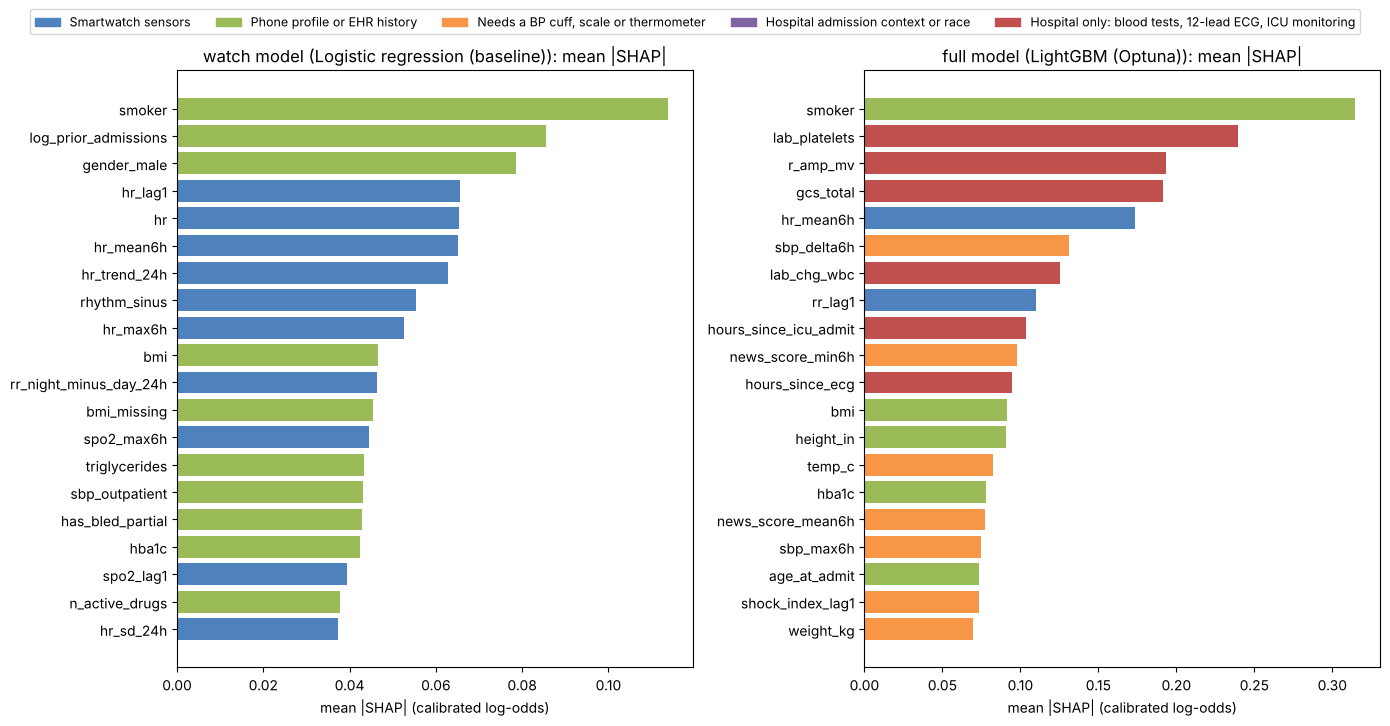

In [4]:
GLOBAL = {}
for s in ["watch", "full"]:
    feats, k = B[s]["features"], cal_slope(s)
    phi = SV[s, "train"] * k
    t = pd.DataFrame({"feature": feats, "mean_abs_shap": np.abs(phi).mean(0),
                      "mean_shap_when_high": [phi[TR[f] > TR[f].median(), i].mean() if TR[f].nunique() > 1 else np.nan
                                              for i, f in enumerate(feats)],
                      "source": [cml.feature_source(f) for f in feats]})
    t["share_%"] = 100 * t.mean_abs_shap / t.mean_abs_shap.sum()
    t["typical_odds_multiplier"] = np.exp(t.mean_abs_shap)
    t = t.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    t.round(4).to_csv(RES / f"shap_global_importance_{s}.csv", index=False)
    GLOBAL[s] = t
    print(f"\n{s} model, top 10 (train patients, calibrated log-odds):")
    print(t.head(10)[["feature", "source", "mean_abs_shap", "share_%"]].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, s in zip(axes, ["watch", "full"]):
    t = GLOBAL[s].head(20).iloc[::-1]
    ax.barh(t.feature, t.mean_abs_shap, color=[SRC_COLOR[x] for x in t.source])
    ax.set(title=f"{s} model ({B[s]['model_type']}): mean |SHAP|", xlabel="mean |SHAP| (calibrated log-odds)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SRC_COLOR.values()]
fig.legend(handles, [cml.SOURCE_LABEL[k].split(" (")[0] for k in SRC_COLOR], loc="upper center", ncol=5, fontsize=9,
           bbox_to_anchor=(0.5, 1.04))
savefig("01_global_importance")

**Result:**
- **Watch model:** smoking, previous admissions and sex lead the single inputs, followed by **6 heart-rate inputs** (current, previous hour, 6 h average, trend, maximum and rhythm). Because the heart-rate signal is split across many inputs, it is the largest driver once they are grouped (see the group chart below).
- **Full model:** smoking, platelets, R-wave amplitude on the ECG, consciousness (GCS) and the 6 h average heart rate lead.

Saved `01_global_importance.png`.

**What this cell does:** draws SHAP beeswarm plots. Each dot is one patient-hour; red means a high value of that input and blue a low one. Dots to the right raise the risk.

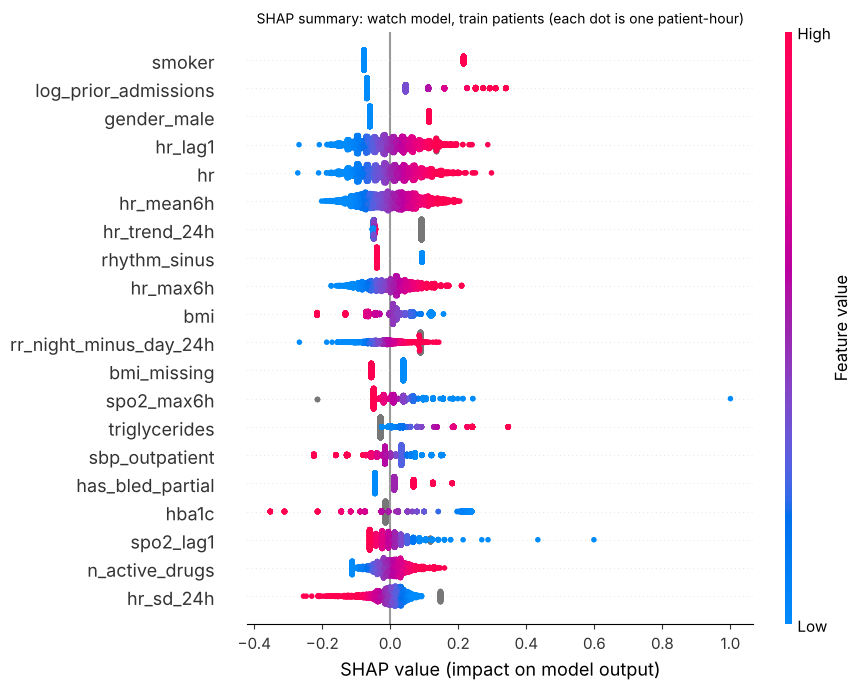

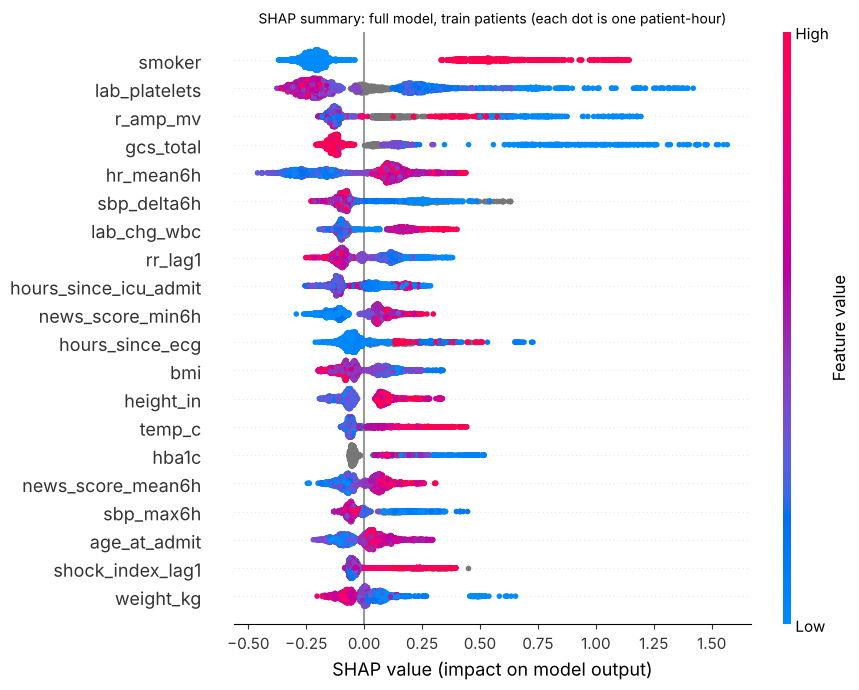

In [5]:
for i, s in enumerate(["watch", "full"]):
    feats = B[s]["features"]
    plt.figure()
    shap.summary_plot(SV[s, "train"] * cal_slope(s), TR[feats].astype(float), max_display=20, show=False, plot_size=(9, 7))
    plt.title(f"SHAP summary: {s} model, train patients (each dot is one patient-hour)", fontsize=10)
    savefig(f"0{2 + i}_beeswarm_{s}")

**Result:** in the watch model, a **high heart rate pushes risk up and a low one pushes it down**, as expected clinically. Smoking, male sex and more previous admissions also raise risk. Saved `02_beeswarm_watch.png` and `03_beeswarm_full.png`.

**What this cell does:** adds up each model's SHAP by data source to show where its information comes from.

               watch  full
source                    
watch           50.0  13.3
phone_profile   50.0  23.1
home_device      0.0  26.0
hospital_only    0.0  37.6


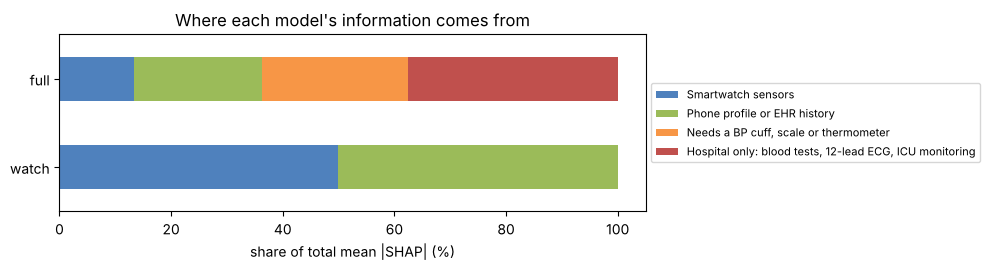

In [6]:
src = pd.concat([GLOBAL[s].groupby("source")["share_%"].sum().rename(s) for s in ["watch", "full"]], axis=1).fillna(0)
src = src.loc[[k for k in SRC_COLOR if k in src.index]]
src.round(1).to_csv(RES / "shap_share_by_source.csv")
print(src.round(1))
ax = src.T.plot.barh(stacked=True, color=[SRC_COLOR[k] for k in src.index], figsize=(10, 2.8))
ax.set(xlabel="share of total mean |SHAP| (%)", title="Where each model's information comes from")
ax.legend([cml.SOURCE_LABEL[k].split(" (")[0] for k in src.index], fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
savefig("04_share_by_source")

**Result:**
- **Watch model:** 50% from the watch sensors and 50% from the phone profile.
- **Full model:** only 13% from signals a watch could give. The rest comes from the profile (23%), BP cuff or thermometer readings (26%) and hospital-only tests (38%).

This explains why the full model ranks patients better in the ICU but cannot run on the phone and watch. Saved `04_share_by_source.png` and `results/explanations/shap_share_by_source.csv`.

**What this cell does:** dependence plots for the watch model's top 6 inputs: how each value changes the odds. Red dots are hours in the 24 h before an event.

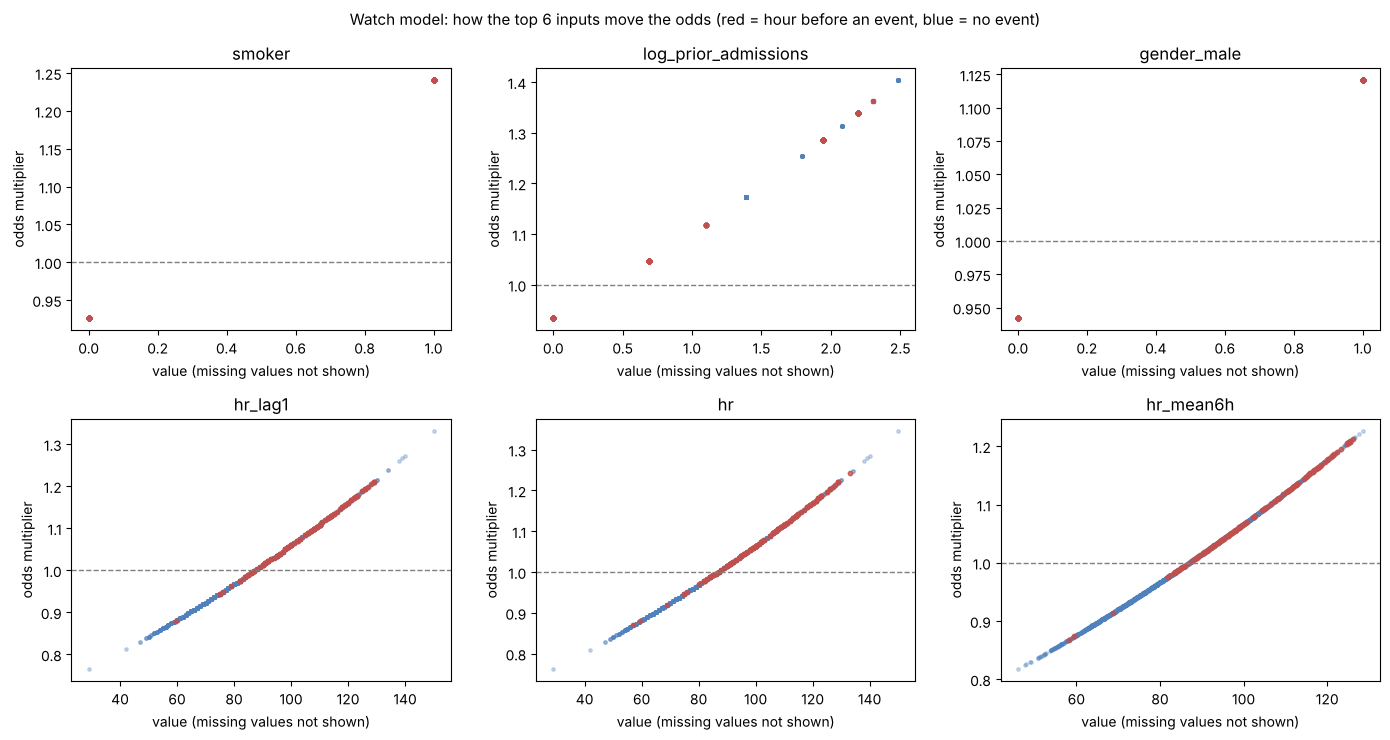

In [7]:
top = GLOBAL["watch"].feature.head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
phi = SV["watch", "train"] * cal_slope("watch")
for ax, f in zip(axes.ravel(), top):
    j = B["watch"]["features"].index(f)
    x = TR[f].astype(float)
    neg, pos = TR.y_24h.values == 0, TR.y_24h.values == 1
    ax.scatter(x[neg], np.exp(phi[neg, j]), s=6, alpha=.3, c=BLUE)
    ax.scatter(x[pos], np.exp(phi[pos, j]), s=10, alpha=.8, c=RED)        # event hours drawn on top
    ax.axhline(1, color=GREY, ls="--", lw=1)
    ax.set(title=f, xlabel="value (missing values not shown)", ylabel="odds multiplier")
fig.suptitle("Watch model: how the top 6 inputs move the odds (red = hour before an event, blue = no event)", fontsize=11)
savefig("05_dependence_watch_top6")

**Result:**
- Smoking raises the odds about ×1.24, and male sex about ×1.12.
- Each extra previous admission adds risk.
- Heart rate moves the odds smoothly, from about ×0.8 at 40 bpm to ×1.3 at 140 bpm.

The lines are straight because a logistic regression cannot learn thresholds; this keeps it stable on few patients. Saved `05_dependence_watch_top6.png`.

## 4 · Plain-language text for every input

**What this cell does:** turns each input into plain language. Every input gets a label, a unit and a sentence pattern, compared with the typical (median) value across all patients. Related inputs are put in **groups** (heart rate, breathing rate, oxygen, rhythm, cholesterol, body size, and so on).

The reports explain by group because the model often splits one signal into opposite pieces. For example, "highest breathing rate lowers risk" can sit next to "average breathing rate raises it". A group's SHAP is the exact sum of its members, so nothing is lost. The cell also adds a **clinical sense check**: when heart rate, breathing rate, oxygen or consciousness pushes risk the opposite way to what medicine expects, the report flags it with ⚠.

In [8]:
# label, unit, kind; kind decides the sentence: level, change, vs (own baseline), flag (yes/no text), or a special formatter
TXT = {
    "hr": ("current heart rate", " bpm", "level"), "hr_lag1": ("heart rate in the previous hour", " bpm", "level"),
    "hr_mean6h": ("average heart rate over the last 6 h", " bpm", "level"), "hr_max6h": ("highest heart rate in the last 6 h", " bpm", "level"),
    "hr_sd_24h": ("heart-rate variability across the day (SD over 24 h)", " bpm", "level"),
    "hr_delta6h": ("heart rate over the last 6 h", " bpm", "change"),
    "hr_trend_24h": ("average heart rate compared with 18 h earlier", " bpm", "change"),
    "hr_vs_baseline": ("heart rate compared with this patient's own normal", " bpm", "vs"),
    "spo2": ("current oxygen saturation", "%", "level"), "spo2_lag1": ("oxygen saturation in the previous hour", "%", "level"),
    "spo2_mean6h": ("average oxygen saturation over 6 h", "%", "level"), "spo2_min6h": ("lowest oxygen saturation in the last 6 h", "%", "level"),
    "spo2_max6h": ("highest oxygen saturation in the last 6 h", "%", "level"),
    "rr": ("current breathing rate", "/min", "level"), "rr_lag1": ("breathing rate in the previous hour", "/min", "level"),
    "rr_mean6h": ("average breathing rate over 6 h", "/min", "level"), "rr_min6h": ("lowest breathing rate in the last 6 h", "/min", "level"),
    "rr_max6h": ("highest breathing rate in the last 6 h", "/min", "level"), "rr_delta6h": ("breathing rate over the last 6 h", "/min", "change"),
    "rr_vs_baseline": ("breathing rate compared with this patient's own normal", "/min", "vs"),
    "rr_night_minus_day_24h": ("night-time breathing rate compared with daytime", "/min", "vs"),
    "tachy_burden_24h": ("time in a fast heart rhythm over the last 24 h", " h", "level"),
    "rhythm_sinus": ("is in normal sinus rhythm", "is not in normal sinus rhythm", "flag"),
    "rhythm_unknown": ("heart rhythm could not be classified this hour", "heart rhythm was classified this hour", "flag"),
    "age_at_admit": ("age", " years", "level"), "bmi": ("BMI", "", "level"),
    "bmi_missing": ("BMI is not recorded", "BMI is recorded", "flag"), "weight_lbs": ("weight", " lb", "level"),
    "height_in": ("height", " in", "level"), "gender_male": ("is male", "is female", "flag"),
    "smoker": ("is a smoker", "is a non-smoker", "flag"),
    "ix_bleeding": ("takes a medicine combination that raises bleeding risk", "has no bleeding-risk medicine combination", "flag"),
    "has_bled_partial": ("bleeding-risk score (HAS-BLED, partial)", "", "level"),
    "ascvd_10y_risk": ("10-year cardiovascular risk (ASCVD)", "%", "pct"), "n_active_drugs": ("number of active medicines", "", "level"),
    "non_hdl": ("non-HDL cholesterol", " mg/dL", "level"), "total_chol": ("total cholesterol", " mg/dL", "level"),
    "ldl": ("LDL cholesterol", " mg/dL", "level"), "triglycerides": ("triglycerides", " mg/dL", "level"),
    "tc_hdl_ratio": ("total/HDL cholesterol ratio", "", "level"), "hba1c": ("HbA1c", "%", "level"),
    "egfr": ("kidney function (eGFR)", " mL/min", "level"), "sbp_outpatient": ("usual clinic systolic BP", " mmHg", "level"),
    "dbp_outpatient": ("usual clinic diastolic BP", " mmHg", "level"),
    "days_since_last_discharge": ("days since the last hospital discharge", "", "discharge"),
    "log_prior_admissions": ("previous hospital admissions", "", "log1p"),
    # full (ICU reference) model only
    "gcs_total": ("consciousness score (GCS, 15 = fully alert)", "", "level"), "weight_kg": ("weight", " kg", "level"),
    "hours_since_icu_admit": ("time since ICU admission", " h", "level"), "hours_since_ecg": ("time since the last 12-lead ECG", " h", "level"),
    "ecg_hr_bpm": ("heart rate on the last ECG", " bpm", "level"), "lab_potassium": ("potassium", " mmol/L", "level"),
    "lab_platelets": ("platelet count", " ×10³/µL", "level"), "lab_calcium": ("calcium", " mg/dL", "level"),
    "lab_log_bun": ("blood urea nitrogen (BUN)", " mg/dL", "exp"), "lab_chg_glucose": ("glucose since the previous test", "", "logchg"),
    "lab_chg_wbc": ("white cell count since the previous test", "", "logchg"),
    "news_score_min6h": ("lowest NEWS2 score in the last 6 h", "", "level"), "news_score_mean6h": ("average NEWS2 score over 6 h", "", "level"),
    "shock_index": ("shock index (heart rate ÷ systolic BP)", "", "level2"), "shock_index_lag1": ("shock index in the previous hour", "", "level2"),
    "shock_index_mean6h": ("average shock index over 6 h", "", "level2"), "sbp_delta6h": ("systolic BP over the last 6 h", " mmHg", "change"),
    "sbp_max6h": ("highest systolic BP in the last 6 h", " mmHg", "level"), "map_min6h": ("lowest mean arterial pressure in 6 h", " mmHg", "level"),
    "map_max6h": ("highest mean arterial pressure in 6 h", " mmHg", "level"),
    "map_vs_baseline": ("mean arterial pressure compared with this patient's own normal", " mmHg", "vs"),
    "temp_c": ("temperature", " °C", "level"), "weight_change_72h": ("weight over the last 72 h", " kg", "change"),
    "r_amp_mv": ("R-wave amplitude on the ECG", " mV", "level2"), "qrs_ms": ("QRS duration on the ECG", " ms", "level"),
    "log_sdnn_ms": ("heart-rate variability on the ECG (SDNN)", " ms", "exp"),
}
missing_txt = [f for s in B for f in B[s]["features"] if f not in TXT]
assert not missing_txt, missing_txt
MED = pd.concat([TR, TE]).median(numeric_only=True)

def num(v, d=0):
    return f"{v:,.{d}f}"

def describe(f, v):
    # one input's value as a short phrase; the typical value comes from all patients in the data
    label, unit, kind = TXT[f]
    if kind == "flag":
        return "the patient " + (label if v == 1 else unit) if not label.startswith(("heart rhythm", "BMI")) else (label if v == 1 else unit)
    if pd.isna(v):
        return f"{label}: not recorded"
    m = MED.get(f, np.nan)
    if kind == "level":
        d = 1 if abs(m) < 20 and f not in ("age_at_admit", "n_active_drugs", "gcs_total") else 0
        return f"{label} is {num(v, d)}{unit} (typical {num(m, d)}{unit})"
    if kind == "level2":
        return f"{label} is {v:.2f}{unit} (typical {m:.2f}{unit})"
    if kind == "pct":
        return f"{label} is {100 * v:.0f}% (typical {100 * m:.0f}%)"
    if kind == "change":
        return f"{label}: " + ("steady" if abs(v) < 0.5 else f"{'up' if v > 0 else 'down'} {num(abs(v), 1 if abs(v) < 10 else 0)}{unit}")
    if kind == "vs":
        return f"{label}: " + ("about the same" if abs(v) < 0.5 else f"{num(abs(v), 1 if abs(v) < 10 else 0)}{unit} {'higher' if v > 0 else 'lower'}")
    if kind == "exp":
        return f"{label} is {np.exp(v):.0f}{unit} (typical {np.exp(m):.0f}{unit})"
    if kind == "logchg":
        return f"{label}: {'up' if v > 0 else 'down'} {100 * abs(np.exp(v) - 1):.0f}%"
    if kind == "log1p":
        return f"{np.expm1(v):.0f} {label}"
    if kind == "discharge":
        return "no earlier hospital stay on record" if v < 0 else f"last discharged from hospital {v:.0f} days ago"
    return f"{label} = {v}"

def effect(phi):
    m = np.exp(phi)
    if m >= 1:
        word = "strongly raises" if m >= 1.5 else "raises" if m >= 1.15 else "slightly raises"
    else:
        word = "strongly lowers" if m <= 1 / 1.5 else "lowers" if m <= 1 / 1.15 else "slightly lowers"
    return word, m

# related inputs are explained together: a model given 7 heart-rate inputs can split one signal into opposite-signed pieces
# (e.g. "highest breathing rate lowers risk" while "average breathing rate raises it"). The sum over a group is still exact SHAP.
GROUPS = {
    "Heart rate": ["hr", "hr_lag1", "hr_mean6h", "hr_max6h", "hr_delta6h", "hr_trend_24h", "hr_vs_baseline", "hr_sd_24h", "ecg_hr_bpm"],
    "Breathing rate": ["rr", "rr_lag1", "rr_mean6h", "rr_min6h", "rr_max6h", "rr_delta6h", "rr_vs_baseline", "rr_night_minus_day_24h"],
    "Oxygen saturation": ["spo2", "spo2_lag1", "spo2_mean6h", "spo2_min6h", "spo2_max6h"],
    "Heart rhythm": ["rhythm_sinus", "rhythm_unknown", "tachy_burden_24h"],
    "Cholesterol": ["total_chol", "ldl", "non_hdl", "triglycerides", "tc_hdl_ratio"],
    "Body size": ["bmi", "bmi_missing", "weight_lbs", "height_in", "weight_kg"],
    "Usual blood pressure": ["sbp_outpatient", "dbp_outpatient"],
    "Blood pressure and shock index": ["sbp_delta6h", "sbp_max6h", "map_min6h", "map_max6h", "map_vs_baseline",
                                       "shock_index", "shock_index_lag1", "shock_index_mean6h"],
    "NEWS2 score": ["news_score_min6h", "news_score_mean6h"],
    "Hospital history": ["log_prior_admissions", "days_since_last_discharge"],
    "Bleeding risk and medicines": ["has_bled_partial", "ix_bleeding", "n_active_drugs"],
    "12-lead ECG": ["r_amp_mv", "qrs_ms", "log_sdnn_ms", "hours_since_ecg"],
}
GROUP_OF = {f: g for g, fs in GROUPS.items() for f in fs}
NAME = {"smoker": "Smoking", "gender_male": "Sex", "age_at_admit": "Age", "hba1c": "HbA1c (diabetes control)",
        "ascvd_10y_risk": "Cardiovascular risk score", "egfr": "Kidney function", "gcs_total": "Consciousness (GCS)",
        "hours_since_icu_admit": "Time in ICU", "temp_c": "Temperature", "weight_change_72h": "Weight change",
        "lab_platelets": "Platelets", "lab_potassium": "Potassium", "lab_calcium": "Calcium", "lab_log_bun": "Urea (BUN)",
        "lab_chg_glucose": "Glucose change", "lab_chg_wbc": "White cell count change"}
def group_of(f):
    return GROUP_OF.get(f, NAME.get(f, TXT[f][0][0].upper() + TXT[f][0][1:]))

# show every input's text once, so the wording can be checked
ex = TE.iloc[len(TE) // 2]
print("\n".join(f"{f:28s} -> {describe(f, ex[f])}" for f in B["full"]["features"][:12] + B["watch"]["features"][:12]))

hr_mean6h                    -> average heart rate over the last 6 h is 78 bpm (typical 86 bpm)
gcs_total                    -> consciousness score (GCS, 15 = fully alert) is 15 (typical 15)
weight_kg                    -> weight is 68 kg (typical 82 kg)
hours_since_icu_admit        -> time since ICU admission is 13 h (typical 31 h)
ascvd_10y_risk               -> 10-year cardiovascular risk (ASCVD) is 21% (typical 10%)
age_at_admit                 -> age is 65 years (typical 60 years)
hours_since_ecg              -> time since the last 12-lead ECG is 10 h (typical 33 h)
ecg_hr_bpm                   -> heart rate on the last ECG is 78 bpm (typical 86 bpm)
lab_potassium                -> potassium is 4.5 mmol/L (typical 3.9 mmol/L)
lab_platelets                -> platelet count is 304 ×10³/µL (typical 218 ×10³/µL)
bmi                          -> BMI is 26 (typical 27)
lab_calcium                  -> calcium is 8.9 mg/dL (typical 8.2 mg/dL)
bmi                          -> BMI is 26 (typi

**Result:** every input of both models has a sentence (the cell stops if any is missing). The printout shows the wording for one test hour, for example "heart rate over the last 6 h: down 12 bpm".

**What this cell does:** ranks the **groups** of related inputs: the reasons a doctor will actually read. Saves `results/explanations/shap_group_importance_*.csv`.

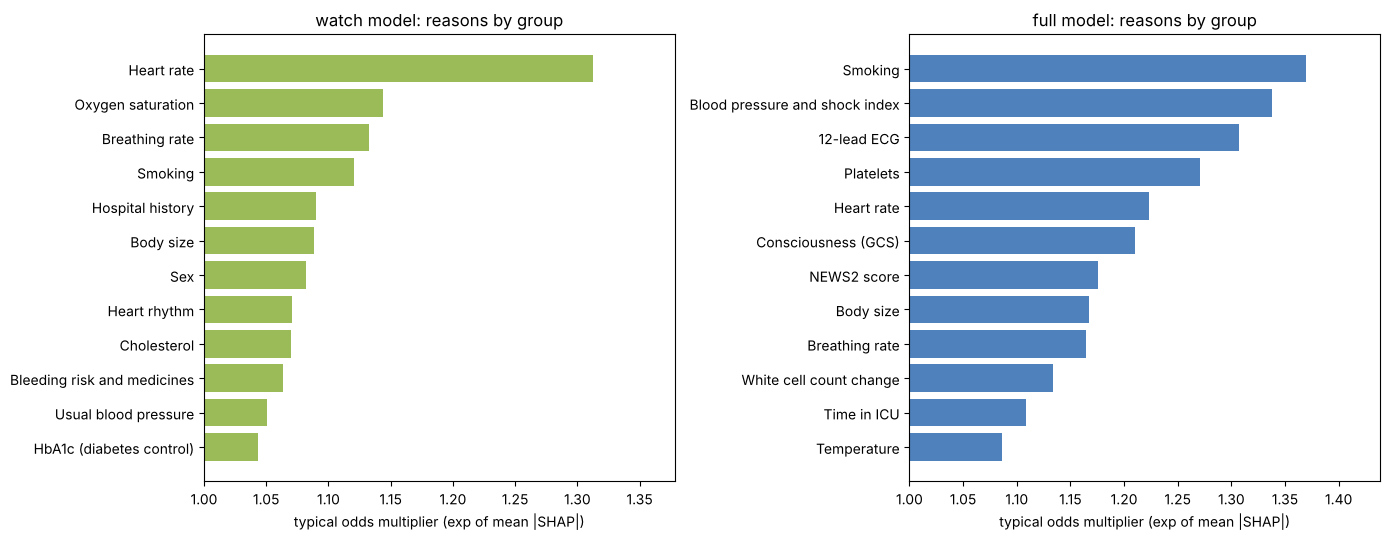

                             watch   full
Heart rate                   0.272  0.201
Oxygen saturation            0.134    NaN
Breathing rate               0.124  0.153
Smoking                      0.114  0.315
Hospital history             0.086    NaN
Body size                    0.085  0.155
Sex                          0.079    NaN
Heart rhythm                 0.068    NaN
Cholesterol                  0.068  0.021
Bleeding risk and medicines  0.062  0.047
Usual blood pressure         0.049    NaN
HbA1c (diabetes control)     0.042  0.078


In [9]:
# global importance by group of related inputs (what a doctor reads), train patients
GG = {}
for s in ["watch", "full"]:
    feats, k = B[s]["features"], cal_slope(s)
    phi = pd.DataFrame(SV[s, "train"] * k, columns=feats).T.groupby([group_of(f) for f in feats]).sum().T
    GG[s] = phi.abs().mean().sort_values(ascending=False).rename("mean_abs_shap")
    GG[s].round(4).to_csv(RES / f"shap_group_importance_{s}.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, s in zip(axes, ["watch", "full"]):
    t = GG[s].head(12).iloc[::-1]
    ax.barh(t.index, np.exp(t.values), color=GREEN if s == "watch" else BLUE)
    ax.set(xlim=(1, None), xlabel="typical odds multiplier (exp of mean |SHAP|)", title=f"{s} model: reasons by group")
savefig("07_group_importance")
print(pd.concat(GG, axis=1).round(3).head(12))

**Result:**
- **Watch model:** heart rate is by far the biggest driver (typical odds effect ×1.31). Oxygen saturation (×1.14), breathing rate (×1.13) and smoking (×1.12) follow.
- **Full model:** smoking, blood pressure and shock index, the 12-lead ECG, platelets and heart rate lead.

Saved `07_group_importance.png`.

## 3b · More global explanations: direction, categories, subgroups, stability, model versions and interactions

**What this cell does:**
- Splits each model's explanation by **input category**: wearable current reading, wearable trend or personal baseline, clinical history, demographics, and hospital measurements.
- Shows, for the top 15 inputs, the **average push up and push down**, kept separate so they do not cancel out.

Saves `shap_share_by_category.csv` and `shap_positive_negative_*.csv`.

                                            watch  full
category                                               
Wearable: current reading                    11.4   0.0
Wearable: trend or personal baseline         38.6  13.3
Clinical history (EHR / profile)             34.9  15.2
Demographic and body size                    15.1  10.1
Hospital measurements (labs, ECG, BP, ICU)    0.0  61.5


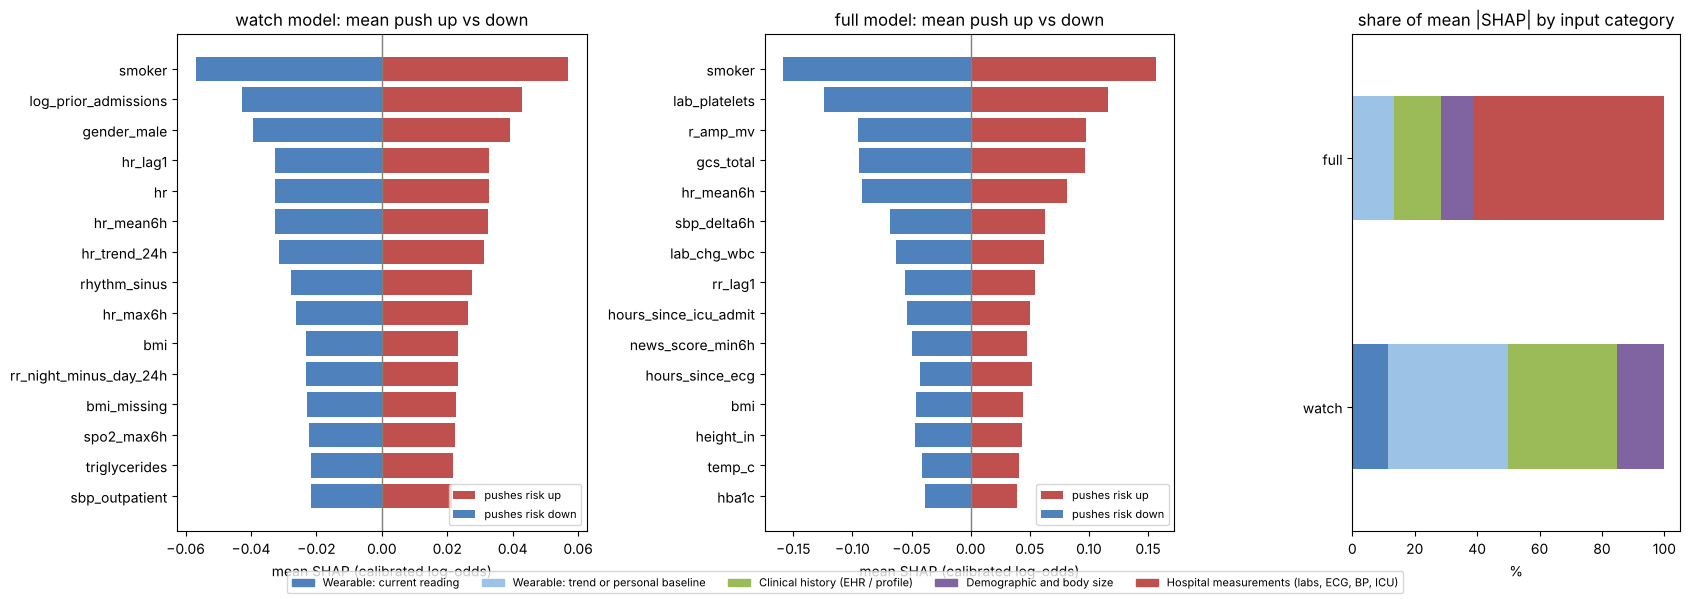

In [10]:
# input categories a clinician thinks in (separate from the data-source tags used above)
TEMPORAL_TAGS = ("_lag1", "mean6h", "max6h", "min6h", "delta6h", "trend", "vs_baseline", "_sd_24h", "burden", "night_minus_day", "change")
def category(f):
    src = cml.feature_source(f)
    if f in ("age_at_admit", "gender_male", "bmi", "bmi_missing", "height_in", "weight_lbs", "weight_kg"):
        return "Demographic and body size"
    if src == "watch":
        return "Wearable: trend or personal baseline" if any(t in f for t in TEMPORAL_TAGS) else "Wearable: current reading"
    if src == "phone_profile":
        return "Clinical history (EHR / profile)"
    return "Hospital measurements (labs, ECG, BP, ICU)"
CAT_COLOR = {"Wearable: current reading": BLUE, "Wearable: trend or personal baseline": "#9cc3e6",
             "Clinical history (EHR / profile)": GREEN, "Demographic and body size": PURPLE,
             "Hospital measurements (labs, ECG, BP, ICU)": RED}

cat = pd.concat([GLOBAL[s].assign(category=GLOBAL[s].feature.map(category)).groupby("category")["share_%"].sum().rename(s)
                 for s in ["watch", "full"]], axis=1).fillna(0).loc[[c for c in CAT_COLOR]]
cat.round(1).to_csv(RES / "shap_share_by_category.csv")
print(cat.round(1))

# positive vs negative contributions: for each input, average push up (when it raises) and down (when it lowers)
fig, axes = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for ax, s in zip(axes[:2], ["watch", "full"]):
    phi = pd.DataFrame(SV[s, "train"] * cal_slope(s), columns=B[s]["features"])
    top = GLOBAL[s].feature.head(15)[::-1]
    pos, neg = phi[top].clip(lower=0).mean(), phi[top].clip(upper=0).mean()
    ax.barh(top, pos, color=RED, label="pushes risk up"); ax.barh(top, neg, color=BLUE, label="pushes risk down")
    ax.axvline(0, color=GREY, lw=1); ax.set(title=f"{s} model: mean push up vs down", xlabel="mean SHAP (calibrated log-odds)")
    ax.legend(fontsize=8, loc="lower right")
    pd.DataFrame({"mean_positive": phi.clip(lower=0).mean(), "mean_negative": phi.clip(upper=0).mean(),
                  "%_hours_positive": 100 * (phi > 0).mean()}).round(4).to_csv(RES / f"shap_positive_negative_{s}.csv")
cat.T.plot.barh(stacked=True, ax=axes[2], color=[CAT_COLOR[c] for c in cat.index], legend=False)
axes[2].set(title="share of mean |SHAP| by input category", xlabel="%")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLOR.values()], list(CAT_COLOR), loc="lower center", ncol=5, fontsize=8)
plt.tight_layout(rect=(0, 0.1, 1, 1))
savefig("08_positive_negative_and_categories")

**Result:**
- **Watch model:** 50% wearable (11% current readings, 39% trends and personal-baseline features), 35% clinical history and 15% demographics. Its strength is change over time, not single readings.
- **Full model:** 62% hospital measurements.
- **Up and down pushes are about equal** for each input. Each input raises risk for some patients and lowers it for others, rather than always pushing one way.

Saved `08_positive_negative_and_categories.png`.

**What this cell does:** repeats the global explanation for **women and men** and for **under 65 and 65+** on the training patients, by reason group. Saves `shap_by_subgroup.csv`.

model  subgroup  patients  hours  event_stays
watch    female        30   2224            6
watch      male        29   1167           10
watch  age < 65        34   2099            7
watch age >= 65        25   1292            9
 full    female        30   2224            6
 full      male        29   1167           10
 full  age < 65        34   2099            7
 full age >= 65        25   1292            9


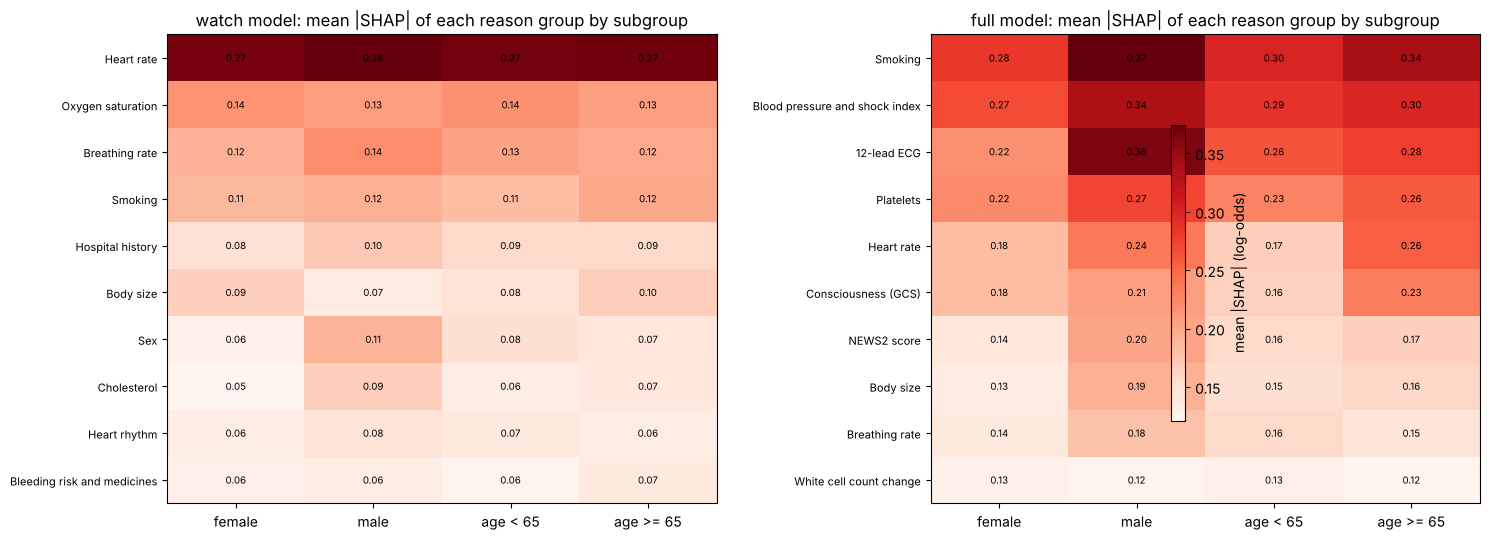

In [11]:
# subgroup explanations (train patients): do the main reasons differ by sex or age band?
SUBGROUPS = {"female": TR.gender_male == 0, "male": TR.gender_male == 1,
             "age < 65": TR.age_at_admit < 65, "age >= 65": TR.age_at_admit >= 65}
rows = []
for s in ["watch", "full"]:
    feats, k = B[s]["features"], cal_slope(s)
    G = pd.DataFrame(SV[s, "train"] * k, columns=feats).T.groupby([group_of(f) for f in feats]).sum().T
    for name, m in SUBGROUPS.items():
        rows.append({"model": s, "subgroup": name, "patients": TR[m].subject_id.nunique(), "hours": int(m.sum()),
                     "event_stays": TR[m & (TR.y_24h == 1)].stay_id.nunique(), **G[m.values].abs().mean().round(4).to_dict()})
SUB = pd.DataFrame(rows)
SUB.to_csv(RES / "shap_by_subgroup.csv", index=False)
print(SUB[["model", "subgroup", "patients", "hours", "event_stays"]].to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, s in zip(axes, ["watch", "full"]):
    t = SUB[SUB.model == s].set_index("subgroup").drop(columns=["model", "patients", "hours", "event_stays"]).dropna(axis=1, how="all")
    t = t[t.mean().sort_values(ascending=False).index[:10]]
    im = ax.imshow(t.T.values, cmap="Reds", aspect="auto")
    ax.set_yticks(range(t.shape[1]), t.columns, fontsize=8); ax.set_xticks(range(len(t)), t.index)
    for (r, c), v in np.ndenumerate(t.T.values):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{s} model: mean |SHAP| of each reason group by subgroup")
plt.colorbar(im, ax=axes, shrink=.7, label="mean |SHAP| (log-odds)")
savefig("09_subgroup_explanations")

**Result:** the watch model relies on the same reasons in every subgroup. Heart rate leads everywhere (0.27 for every group), and oxygen and breathing come next. Body size matters a little more for women and over-65s. Each subgroup has only 6-10 event stays, so this is a check for big differences, not a fairness proof. Saved `09_subgroup_explanations.png`.

**What this cell does:** resamples the training patients 200 times and recomputes the global ranking each time. It reports how often each input stays in the top 10, and how well the whole ranking agrees (Kendall tau). Saves `shap_global_stability.csv`.

watch: Kendall tau of the full ranking vs the 200 resamples: median 0.91 (5th-95th percentile 0.85-0.94)


full: Kendall tau of the full ranking vs the 200 resamples: median 0.94 (5th-95th percentile 0.90-0.96)


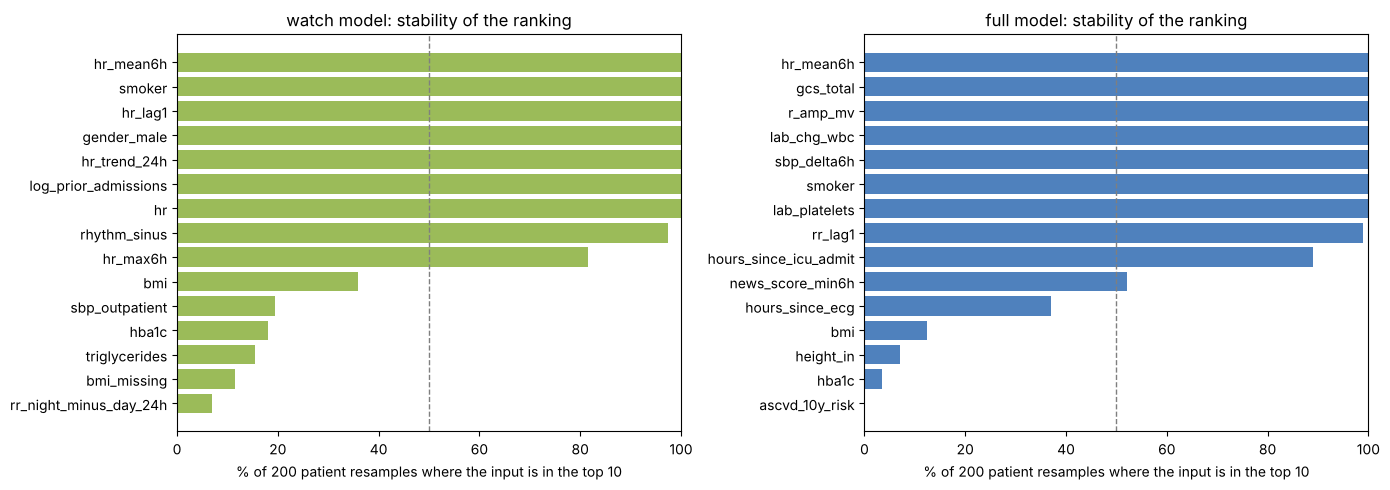

In [12]:
# stability: resample train patients 200 times and see how often each input stays in the global top 10
rng = np.random.default_rng(SEED)
pats = TR.subject_id.unique()
STAB = {}
for s in ["watch", "full"]:
    A = pd.DataFrame(np.abs(SV[s, "train"]), columns=B[s]["features"]).assign(pid=TR.subject_id.values).groupby("pid").sum()
    n_rows = TR.groupby("subject_id").size()
    hits, taus = pd.Series(0, index=B[s]["features"]), []
    ref = GLOBAL[s].set_index("feature").mean_abs_shap
    for _ in range(200):
        pick = rng.choice(pats, len(pats), replace=True)
        imp = A.loc[pick].sum() / n_rows.loc[pick].sum()
        hits[imp.nlargest(10).index] += 1
        taus.append(imp.rank().corr(ref.reindex(imp.index).rank(), method="kendall"))
    STAB[s] = (100 * hits / 200).sort_values(ascending=False)
    print(f"{s}: Kendall tau of the full ranking vs the 200 resamples: median {np.median(taus):.2f} "
          f"(5th-95th percentile {np.percentile(taus, 5):.2f}-{np.percentile(taus, 95):.2f})")
pd.concat(STAB, axis=1).round(1).to_csv(RES / "shap_global_stability.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, s in zip(axes, ["watch", "full"]):
    t = STAB[s].head(15)[::-1]
    ax.barh(t.index, t.values, color=GREEN if s == "watch" else BLUE)
    ax.axvline(50, color=GREY, ls="--", lw=1)
    ax.set(xlim=(0, 100), xlabel="% of 200 patient resamples where the input is in the top 10", title=f"{s} model: stability of the ranking")
savefig("10_global_stability")

**Result:** the ranking is stable. The median Kendall tau is **0.91** for the watch model and **0.94** for the full model, where 1 means identical. The watch model's heart-rate inputs, smoking, sex and previous admissions are in the top 10 in **100% of resamples**. Saved `10_global_stability.png`.

**What this cell does:** compares the deployed models' explanations with the **other candidate models** notebook 05 trained on the same data. Round 1's models were replaced, so these candidates are the other versions available. It also adds `compare_versions()`, which checks a future retrained model's SHAP ranking against today's. Saves `shap_model_version_comparison.csv`.

watch: deployed Logistic regression (baseline) vs candidate LightGBM (Optuna): Spearman rank correlation of reason groups = 0.70; top 3 deployed ['Heart rate', 'Breathing rate', 'Body size'], top 3 candidate ['Heart rate', 'Body size', 'Breathing rate']


watch: deployed Logistic regression (baseline) vs candidate Random forest: Spearman rank correlation of reason groups = 0.77; top 3 deployed ['Heart rate', 'Breathing rate', 'Body size'], top 3 candidate ['Heart rate', 'Body size', 'Smoking']
full: deployed LightGBM (Optuna) vs candidate Logistic regression (baseline): Spearman rank correlation of reason groups = 0.69; top 3 deployed ['Blood pressure and shock index', '12-lead ECG', 'Smoking'], top 3 candidate ['Blood pressure and shock index', 'Heart rate', 'Body size']


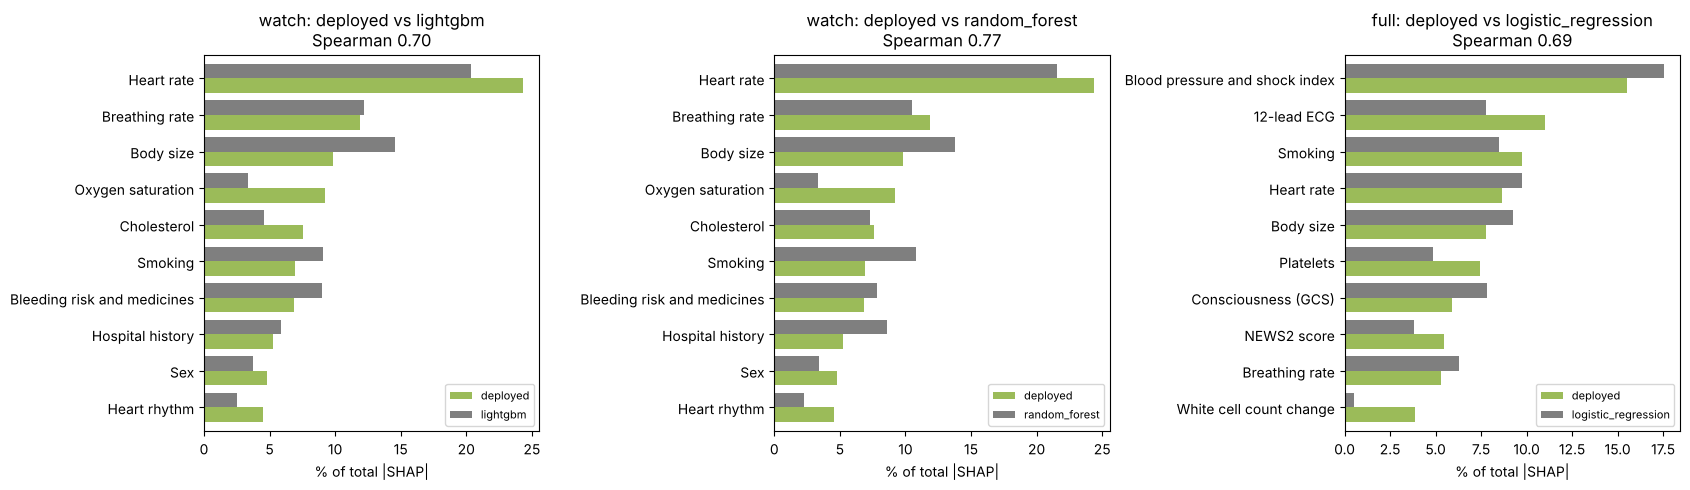

self-check of the helper: {'spearman': np.float64(1.0), 'entered_top': [], 'left_top': []}


In [13]:
# model-version comparison: the deployed models against the other candidate models notebook 05 trained on the same data.
# (Round-1 models were replaced in notebook 05, so these candidates are the other "versions" available today.)
def global_groups(s, est, feats, kind):
    X = TR[feats].astype(float)
    if kind == "tree":
        phi = shap.TreeExplainer(est)(X).values
    else:
        phi, _ = shap_linear({"estimator": est, "features": feats}, TR, TR)
    phi = phi if phi.ndim == 2 else phi[..., -1]
    return pd.DataFrame(np.abs(phi), columns=feats).T.groupby([group_of(f) for f in feats]).sum().T.mean()

VERS = {}
for s, other in [("watch", "lightgbm"), ("watch", "random_forest"), ("full", "logistic_regression")]:
    c = joblib.load(MODELS / "candidates" / f"{s}_{other}.pkl")
    kind = "linear" if other == "logistic_regression" else "tree"
    if other == "random_forest":                      # TreeExplainer on a forest: a 600-hour sample keeps this quick
        idx = np.random.default_rng(SEED).choice(len(TR), 600, replace=False)
        phi = shap.TreeExplainer(c["estimator"])(TR.iloc[idx][c["features"]].astype(float)).values[..., -1]
        g = pd.DataFrame(np.abs(phi), columns=c["features"]).T.groupby([group_of(f) for f in c["features"]]).sum().T.mean()
    else:
        g = global_groups(s, c["estimator"], c["features"], kind)
    dep = pd.DataFrame(np.abs(SV[s, "train"]), columns=B[s]["features"]).T.groupby([group_of(f) for f in B[s]["features"]]).sum().T.mean()
    both = pd.concat([dep.rename("deployed"), g.rename(other)], axis=1).fillna(0)
    rho = both.deployed.rank().corr(both[other].rank(), method="spearman")
    VERS[f"{s}: deployed vs {other}"] = (both, rho)
    print(f"{s}: deployed {B[s]['model_type']} vs candidate {c['model']}: Spearman rank correlation of reason groups = {rho:.2f}; "
          f"top 3 deployed {list(dep.nlargest(3).index)}, top 3 candidate {list(g.nlargest(3).index)}")
pd.concat({k: v[0] for k, v in VERS.items()}, axis=1).round(4).to_csv(RES / "shap_model_version_comparison.csv")
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (k, (both, rho)) in zip(axes, VERS.items()):
    t = (both / both.sum() * 100).sort_values("deployed").tail(10)
    t.plot.barh(ax=ax, color=[GREEN, GREY], width=.8)
    ax.set(title=f"{k}\nSpearman {rho:.2f}", xlabel="% of total |SHAP|"); ax.legend(fontsize=8)
savefig("11_model_version_comparison")

# a reusable helper for later retrains: compare a new global-importance file with this one
def compare_versions(old_csv, new_csv, top=10):
    a, b = (pd.read_csv(p).set_index("feature").mean_abs_shap for p in (old_csv, new_csv))
    j = pd.concat([a.rename("old"), b.rename("new")], axis=1).fillna(0)
    return {"spearman": round(j.old.rank().corr(j.new.rank(), method="spearman"), 3),
            "entered_top": sorted(set(b.nlargest(top).index) - set(a.nlargest(top).index)),
            "left_top": sorted(set(a.nlargest(top).index) - set(b.nlargest(top).index))}
print("self-check of the helper:", compare_versions(RES / "shap_global_importance_watch.csv", RES / "shap_global_importance_watch.csv"))

**Result:** the candidates agree on the main reasons. Spearman rank correlation of the reason groups is 0.70 (watch LR vs LightGBM), 0.77 (watch LR vs random forest) and 0.69 (full LightGBM vs LR). **Heart rate is top for all three watch models.** Saved `11_model_version_comparison.png`.

**What this cell does:** SHAP **interaction** values.
- **Watch model:** a logistic regression is additive, so it has no interactions by construction.
- **Full LightGBM model:** exact TreeExplainer interaction values on 600 train hours, giving the strongest pairs and a plot of the top one.

Saves `shap_interactions_full.csv`.

interaction share of total explanation: 45.5%
                                         mean |interaction| (both halves)  \
hours_since_icu_admit smoker                                        0.051   
smoker                height_in                                     0.049   
hr_mean6h             lab_platelets                                 0.042   
hours_since_ecg       smoker                                        0.038   
hr_mean6h             age_at_admit                                  0.033   
lab_platelets         qrs_ms                                        0.033   
hr_mean6h             bmi                                           0.031   
lab_platelets         sbp_delta6h                                   0.031   
hr_mean6h             lab_potassium                                 0.030   
r_amp_mv              news_score_mean6h                             0.030   

                                         as % of the larger main effect  
hours_since_icu_admit smoker    

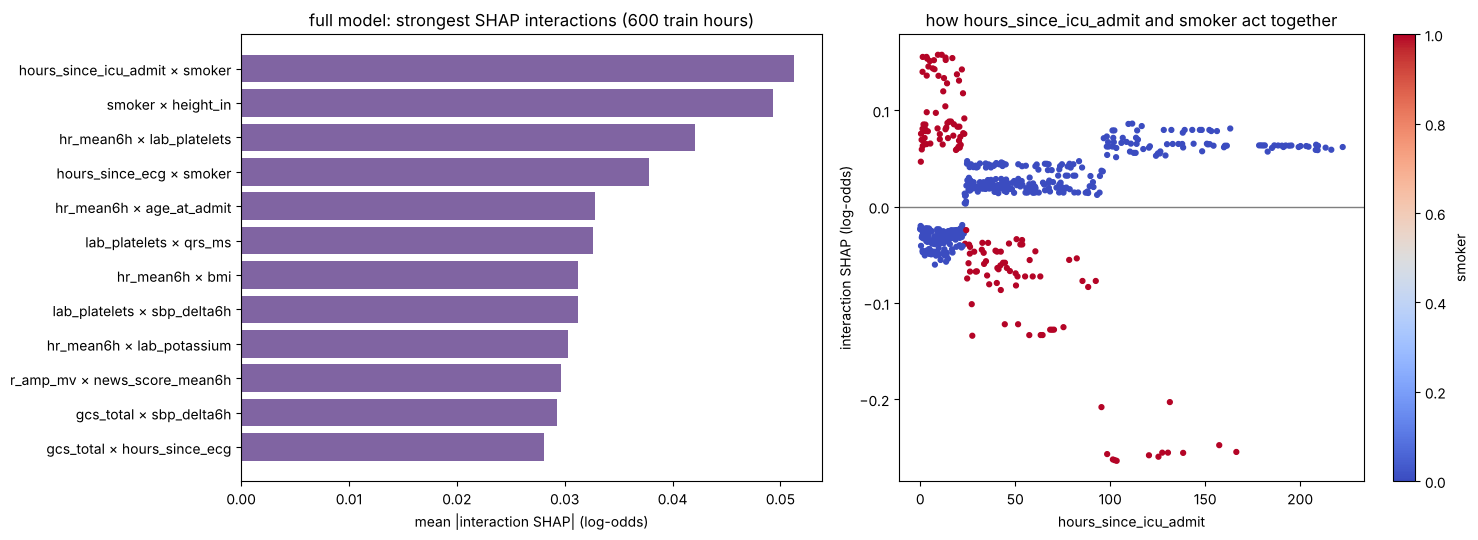

In [14]:
# SHAP interactions. The watch model is a logistic regression: it is additive by construction, so every interaction is exactly 0.
# The full LightGBM model can learn interactions: exact TreeExplainer interaction values on 600 train hours.
idx = np.random.default_rng(SEED).choice(len(TR), 600, replace=False)
Xs = TR.iloc[idx][B["full"]["features"]].astype(float)
IV = shap.TreeExplainer(B["full"]["estimator"]).shap_interaction_values(Xs)
IV = IV[-1] if isinstance(IV, list) else IV
feats = B["full"]["features"]
mi = np.abs(IV).mean(0) * cal_slope("full")
main = pd.Series(np.diag(mi), index=feats)
pairs = pd.Series({(feats[a], feats[b]): 2 * mi[a, b] for a in range(len(feats)) for b in range(a + 1, len(feats))}).sort_values(ascending=False)
inter = pairs.head(15).rename("mean |interaction| (both halves)").to_frame()
inter["as % of the larger main effect"] = [100 * v / max(main[a], main[b]) for (a, b), v in inter.iloc[:, 0].items()]
inter.round(4).to_csv(RES / "shap_interactions_full.csv")
print(f"interaction share of total explanation: {100 * (mi.sum() - np.trace(mi)) / mi.sum():.1f}%")
print(inter.head(10).round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = inter.head(12).iloc[::-1]
axes[0].barh([f"{a} × {b}" for a, b in t.index], t.iloc[:, 0], color=PURPLE)
axes[0].set(title="full model: strongest SHAP interactions (600 train hours)", xlabel="mean |interaction SHAP| (log-odds)")
a, b = inter.index[0]
ia, ib = feats.index(a), feats.index(b)
sc = axes[1].scatter(Xs[a], 2 * IV[:, ia, ib] * cal_slope("full"), c=Xs[b], cmap="coolwarm", s=12)
plt.colorbar(sc, ax=axes[1], label=b)
axes[1].axhline(0, color=GREY, lw=1)
axes[1].set(xlabel=a, ylabel="interaction SHAP (log-odds)", title=f"how {a} and {b} act together")
savefig("12_interactions_full")

**Result:**
- **Interactions carry 45% of the full model's explanation.** Its trees combine inputs a lot, while the watch model keeps them separate.
- **Top pairs:** time in ICU × smoking, smoking × height, 6 h heart rate × platelets, and heart rate × age.
- **The smoking effect changes over time:** it adds risk early in the ICU stay and less later. This is a pattern in 59 patients, not a clinical finding.

Saved `12_interactions_full.png`.

## 5 · Patient risk scores with their top reasons (test patients)

**What this cell does:** scores every test stay at its **latest hour**, the moment a doctor would open the app. For each stay it gives:
- **Risk and tier:** Low, Moderate or High, from the cut-offs fixed in notebook 05.
- **Reasons:** the top 3 groups raising the risk and the top 2 lowering it.
- **Stay history:** the peak risk over the stay and the hours spent at High.
- **Data freshness:** hours since the watch last sent heart rate, SpO2 and breathing rate (OK / CHECK / STALE).

It also saves the per-hour SHAP values of every test hour.

In [15]:
TIERS = {s: B[s]["operating_points"] for s in B}
def tier(s, p):
    t = TIERS[s]
    return "High" if p >= t["high"] else "Moderate" if p >= t["moderate"] else "Low"

def grouped(s, phi_row):
    # exact SHAP per group of related inputs, in calibrated log-odds
    k, feats = cal_slope(s), B[s]["features"]
    g = pd.Series(phi_row * k, index=feats)
    return g.groupby([group_of(f) for f in feats]).sum(), g

# clinical sense check: for these signals medicine expects a clear direction (+1: higher is worse, -1: lower is worse)
EXPECT = {"Heart rate": ("hr", +1), "Breathing rate": ("rr", +1), "Oxygen saturation": ("spo2", -1), "Consciousness (GCS)": ("gcs_total", -1)}
WARN = " ⚠ This direction goes against usual clinical expectation; the model learned it from few patients, so do not rely on it."

def against_expectation(name, x, row):
    if name not in EXPECT:
        return False
    f, e = EXPECT[name]
    v, m = row[f], MED[f]
    return bool(pd.notna(v) and abs(v - m) > 0.1 * abs(m) and np.sign(v - m) * e != np.sign(x))

def reasons(s, phi_row, row, n_up=3, n_down=2):
    gsum, g = grouped(s, phi_row)
    def fmt(name, x):
        members = [f for f in g.index if group_of(f) == name]
        # show the members pushing the same way as the group, largest first, at most 2
        shown = sorted([f for f in members if np.sign(g[f]) == np.sign(x)] or members, key=lambda f: -abs(g[f]))[:2]
        detail = "; ".join(describe(f, row[f]) for f in shown)
        warn = against_expectation(name, x, row)
        return {"reason": name, "odds_multiplier": round(float(np.exp(x)), 2), "inputs": ", ".join(members), "warning": warn,
                "text": f"{name}: {detail}. This {effect(x)[0]} the risk (×{np.exp(x):.2f})" + (WARN if warn else "")}
    up = [fmt(n, x) for n, x in gsum.sort_values(ascending=False).items() if x > 0][:n_up]
    down = [fmt(n, x) for n, x in gsum.sort_values().items() if x < 0][:n_down]
    return up, down

for s in ["watch", "full"]:
    TE[f"tier_{s}"] = [tier(s, p) for p in TE[f"risk_{s}"]]

# hourly test explanations: every input's contribution, as calibrated log-odds
for s in ["watch", "full"]:
    out = TE[["subject_id", "stay_id", "hour", "y_24h", "hours_to_event", f"risk_{s}", f"tier_{s}"]].copy()
    out[B[s]["features"]] = np.round(SV[s, "test"] * cal_slope(s), 4)
    out.to_csv(RES / f"shap_values_test_{s}.csv", index=False)

def freshness(g):
    # hours since the watch last delivered each signal (from the *_measured flags), at the report hour
    last = g.iloc[-1]
    out = {}
    for sig in ["hr", "spo2", "rr"]:
        m = g[f"{sig}_measured"].fillna(0) > 0
        out[sig] = int((last.hour - g.hour[m].max()).total_seconds() // 3600) if m.any() else None
    status = "OK" if all(v is not None and v <= 2 for v in out.values()) else "STALE"      # same 2 h rule as the data-quality check
    return out, status

ROWS = []
for sid, g in TE.groupby("stay_id"):
    g = g.sort_values("hour"); i = g.index[-1]; row = TE.loc[i]
    fr, status = freshness(g)
    rec = {"subject_id": int(row.subject_id), "stay_id": int(sid), "report_hour": row.hour, "hours_monitored": len(g),
           "event_within_24h_of_report": int(row.y_24h), "stay_has_event": int(g.y_24h.max()),
           "hours_since_hr": fr["hr"], "hours_since_spo2": fr["spo2"], "hours_since_rr": fr["rr"], "data_status": status}
    for s in ["watch", "full"]:
        up, down = reasons(s, SV[s, "test"][i], row)
        hi = g[f"risk_{s}"] >= TIERS[s]["high"]
        rec.update({f"risk_{s}": round(float(row[f"risk_{s}"]), 4), f"tier_{s}": row[f"tier_{s}"],
                    f"peak_risk_{s}": round(float(g[f"risk_{s}"].max()), 4), f"hours_high_{s}": int(hi.sum()),
                    **{f"{s}_up{n + 1}": r["text"] for n, r in enumerate(up)},
                    **{f"{s}_down{n + 1}": r["text"] for n, r in enumerate(down)}})
    ROWS.append(rec)
SCORES = pd.DataFrame(ROWS).sort_values("risk_watch", ascending=False).reset_index(drop=True)
SCORES.to_csv(RES / "patient_scores_test.csv", index=False)
pd.set_option("display.max_colwidth", 90)
print(SCORES[["subject_id", "stay_id", "hours_monitored", "risk_watch", "tier_watch", "risk_full", "tier_full", "data_status",
              "stay_has_event"]].to_string(index=False))
print("\nexample reasons (highest watch risk):")
for c in ["watch_up1", "watch_up2", "watch_up3", "watch_down1"]:
    print(" ", SCORES.loc[0, c])

 subject_id  stay_id  hours_monitored  risk_watch tier_watch  risk_full tier_full data_status  stay_has_event
   10015931 37093652               12      0.1274       High     0.0140       Low          OK               1
   10026255 38229329               23      0.1193       High     0.1177      High       STALE               0
   10026255 31248398               21      0.1036       High     0.1828      High       STALE               0
   10005817 31316840              226      0.0806       High     0.2061      High          OK               1
   10004733 39635619               23      0.0548   Moderate     0.0418       Low          OK               1
   10007058 32506122               45      0.0520   Moderate     0.0032       Low          OK               0
   10020740 32145159               24      0.0516   Moderate     0.0245       Low          OK               0
   10022880 39623478               17      0.0453   Moderate     0.0067       Low          OK               0
   1003999

**Result (19 test stays from 15 patients):**
- **Watch model at report time:** 4 High, 9 Moderate, 6 Low.
- **Event stays:** 3 of the 4 stays that had an event score High (37093652, 31316840) or Moderate (39635619). The 4th (35026312, the lactate event) is Low, as in notebook 05.
- **Highest risk:** stay 37093652 at 12.7%, mainly for heart rate (118 bpm vs typical 86 → odds ×1.75), low body weight and a high bleeding-risk score.
- **Data freshness:** OK for all 19 stays, because the test data is hourly ICU monitoring.

Saved `results/explanations/patient_scores_test.csv` and `shap_values_test_*.csv`.

**What this cell does:** counts which reason groups appear most often in the top 3 when the watch model is at Moderate or High: what doctors will see most.

759 test hours at Moderate or High
                             % of alert hours         source
Smoking                                  52.0  phone_profile
Oxygen saturation                        46.4          watch
Heart rate                               37.9          watch
Sex                                      33.9  phone_profile
Bleeding risk and medicines              30.0  phone_profile
HbA1c (diabetes control)                 28.3  phone_profile
Breathing rate                           20.2          watch
Body size                                15.9  phone_profile
Cholesterol                              14.9  phone_profile
Heart rhythm                              9.4          watch
Kidney function                           6.1  phone_profile
Usual blood pressure                      5.0  phone_profile


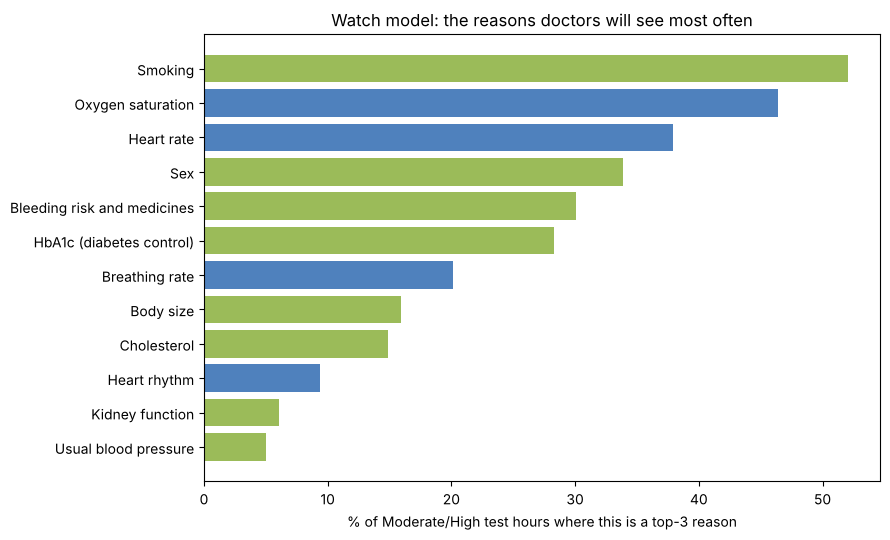

In [16]:
# how often each input appears among the top-3 raising reasons when the watch model is at Moderate or High
s = "watch"; k = cal_slope(s); feats = B[s]["features"]
mask = TE[f"risk_{s}"] >= TIERS[s]["moderate"]
phi = SV[s, "test"][mask.values] * k
G = pd.DataFrame(phi, columns=feats).T.groupby([group_of(f) for f in feats]).sum().T
cnt = pd.Series([n for _, r in G.iterrows() for n, x in r.nlargest(3).items() if x > 0]).value_counts()
freq = (100 * cnt / mask.sum()).rename("% of alert hours").to_frame()
freq["source"] = [cml.feature_source(next(f for f in feats if group_of(f) == n)) for n in freq.index]
freq.round(1).to_csv(RES / "top_reason_frequency_watch.csv")
print(f"{mask.sum()} test hours at Moderate or High")
print(freq.head(12).round(1))
t = freq.head(15).iloc[::-1]
plt.figure(figsize=(9, 5.5))
plt.barh(t.index, t["% of alert hours"], color=[SRC_COLOR[x] for x in t.source])
plt.xlabel("% of Moderate/High test hours where this is a top-3 reason")
plt.title("Watch model: the reasons doctors will see most often")
savefig("06_top_reason_frequency_watch")

**Result (759 test hours at Moderate or High):**
- **Most frequent:** smoking (52%), oxygen saturation (46%), heart rate (38%), sex (34%), bleeding risk and medicines (30%) and HbA1c (28%).
- **Profile inputs** (smoking, sex, HbA1c) are fixed for a patient, so they act like a baseline risk. **Watch signals** (oxygen, heart rate, breathing) explain the changes from hour to hour.

Saved `06_top_reason_frequency_watch.png`.

**What this cell does:** defines the **patient card**: the risk over the stay (both models, with the Moderate and High lines and the event, if any) next to the reason groups as odds multipliers. Cards are drawn when the reports are written in section 8.

In [17]:
def patient_card(sid, path):
    g = TE[TE.stay_id == sid].sort_values("hour")
    i = g.index[-1]; row = TE.loc[i]
    hrs = (g.hour - g.hour.iloc[-1]).dt.total_seconds() / 3600
    fig = plt.figure(figsize=(13, 4.6))
    ax = fig.add_axes([0.05, 0.14, 0.50, 0.74])
    ax.plot(hrs, g.risk_watch, color=GREEN, label="watch model")
    ax.plot(hrs, g.risk_full, color=BLUE, alpha=.6, label="full ICU model")
    ax.axhline(TIERS["watch"]["high"], color=RED, ls="--", lw=1, label="High (watch)")
    ax.axhline(TIERS["watch"]["moderate"], color=ORANGE, ls="--", lw=1, label="Moderate (watch)")
    ev = g[g.hours_to_event.notna()]
    if g.y_24h.max() == 1 and len(ev):
        t_ev = hrs.iloc[-1] + float(ev.hours_to_event.iloc[-1]) + 1
        ax.axvline(t_ev, color=RED, lw=2); ax.text(t_ev, ax.get_ylim()[1] * .95, " event", color=RED, fontsize=8, va="top")
    ax.set(xlabel="hours before the report time", ylabel="24 h risk", title=f"Patient {int(row.subject_id)}, stay {sid}: risk over time")
    ax.legend(fontsize=7, loc="upper left")
    ax2 = fig.add_axes([0.70, 0.14, 0.28, 0.74])
    gs = grouped("watch", SV["watch", "test"][i])[0]
    gs = gs.reindex(gs.abs().sort_values().index)[-8:]
    ax2.barh(gs.index, np.exp(gs.values) - 1, left=1, color=[RED if x > 0 else BLUE for x in gs.values])
    ax2.axvline(1, color=GREY, lw=1)
    ax2.set(xlabel="odds multiplier", title=f"Watch risk {row.risk_watch:.1%} ({row.tier_watch}): top reasons")
    plt.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)

**Result:** function ready.

## 6 · Patient-level explanation records, waterfalls and reference ranges

**What this cell does:** builds a full **explanation record** for each test stay and each model. A record holds:
- The **output space:** calibrated log-odds.
- The **base (average patient) log-odds and probability**, and the **patient's log-odds and probability**.
- For every input: its value and unit; its documented **reference range** (AHA, WHO, ADA, NCEP, KDIGO or NEWS2) and whether the value is in range; the population typical value; the **personal baseline** (for heart rate, breathing and SpO2); its **provenance**; its SHAP value, odds multiplier and explanation share.

It checks that base + SHAP reproduces every saved risk. Saves `patient_explanation_records.csv`.

In [18]:
# documented adult reference ranges, shown next to values; they are context, not SHAP importance
REF = {
    "hr": ("60-100 bpm", 60, 100, "AHA, adult resting heart rate"), "spo2": ("95-100%", 95, 100, "typical healthy adult; BTS hospital target 94-98%"),
    "rr": ("12-20 /min", 12, 20, "NEWS2 (RCP 2017) scores 12-20 as normal"), "temp_c": ("36.1-38.0 °C", 36.1, 38.0, "NEWS2 (RCP 2017)"),
    "bmi": ("18.5-24.9", 18.5, 24.9, "WHO adult BMI"), "hba1c": ("< 5.7%", None, 5.7, "ADA: 5.7-6.4% prediabetes, >= 6.5% diabetes"),
    "ldl": ("< 100 mg/dL", None, 100, "NCEP ATP III optimal"), "total_chol": ("< 200 mg/dL", None, 200, "NCEP ATP III desirable"),
    "triglycerides": ("< 150 mg/dL", None, 150, "NCEP ATP III normal"), "non_hdl": ("< 130 mg/dL", None, 130, "NCEP ATP III goal"),
    "egfr": (">= 90 mL/min", 90, None, "KDIGO G1"), "sbp_outpatient": ("< 120 mmHg", None, 120, "ACC/AHA 2017 normal"),
    "dbp_outpatient": ("< 80 mmHg", None, 80, "ACC/AHA 2017 normal"), "gcs_total": ("15", 15, 15, "fully alert"),
    "lab_potassium": ("3.5-5.0 mmol/L", 3.5, 5.0, "typical adult lab range; local ranges vary"),
    "lab_platelets": ("150-450 ×10³/µL", 150, 450, "typical adult lab range; local ranges vary"),
    "lab_calcium": ("8.5-10.2 mg/dL", 8.5, 10.2, "typical adult lab range; local ranges vary"),
}
for f in ["hr_lag1", "hr_mean6h", "hr_max6h"]: REF[f] = REF["hr"]
for f in ["spo2_lag1", "spo2_mean6h", "spo2_min6h", "spo2_max6h"]: REF[f] = REF["spo2"]
for f in ["rr_lag1", "rr_mean6h", "rr_min6h", "rr_max6h"]: REF[f] = REF["rr"]

def ref_flag(f, v):
    if f not in REF or pd.isna(v):
        return ""
    _, lo, hi, _ = REF[f]
    return "below range" if lo is not None and v < lo else "above range" if hi is not None and v > hi else "in range"

def provenance(f, v):
    # where a value comes from in the phone + watch deployment, and whether the model filled it in
    src = cml.feature_source(f)
    base = {"watch": "wearable (derived over time)" if any(t in f for t in TEMPORAL_TAGS) else "wearable (direct reading)",
            "phone_profile": "EHR / phone profile", "home_device": "home device or ICU monitor",
            "hospital_context": "hospital record", "hospital_only": "lab / 12-lead ECG / ICU (EHR)"}[src]
    return base + (" · missing, filled by the model" if pd.isna(v) else "")

def personal_baseline(f, row):
    # the patient's own normal so far in this stay (expanding median), available for HR, breathing rate and SpO2
    root = f.split("_")[0]
    if root in ("hr", "rr", "spo2") and f"{root}_vs_baseline" in row and pd.notna(row[f"{root}_vs_baseline"]) and pd.notna(row[root]):
        return float(row[root] - row[f"{root}_vs_baseline"])
    return np.nan

UNIT = {f: (v[1] if v[2] not in ("flag",) else "") for f, v in TXT.items()}
def explanation_record(s, i):
    row, k = TE.loc[i], cal_slope(s)
    phi = SV[s, "test"][i] * k
    base = BASE[s] * k + (float(B[s]["calibrator"].model.intercept_[0]) if B[s]["calibrator"].method == "sigmoid" else 0.0)
    out_lo = base + phi.sum()
    t = pd.DataFrame({"feature": B[s]["features"], "group": [group_of(f) for f in B[s]["features"]],
                      "category": [category(f) for f in B[s]["features"]],
                      "value": [row[f] for f in B[s]["features"]], "unit": [UNIT.get(f, "") for f in B[s]["features"]],
                      "reference_range": [REF.get(f, ("",))[0] for f in B[s]["features"]],
                      "vs_reference": [ref_flag(f, row[f]) for f in B[s]["features"]],
                      "population_typical": [MED.get(f, np.nan) for f in B[s]["features"]],
                      "personal_baseline": [personal_baseline(f, row) for f in B[s]["features"]],
                      "provenance": [provenance(f, row[f]) for f in B[s]["features"]],
                      "shap_log_odds": phi, "odds_multiplier": np.exp(phi),
                      "explanation_share_%": 100 * np.abs(phi) / np.abs(phi).sum()})
    t["direction"] = np.where(t.shap_log_odds > 0, "raises", "lowers")
    head = {"model": s, "output_space": "calibrated log-odds of deterioration within 24 h", "base_log_odds": round(base, 4),
            "base_probability": round(1 / (1 + np.exp(-base)), 4), "output_log_odds": round(out_lo, 4),
            "output_probability": round(1 / (1 + np.exp(-out_lo)), 4), "saved_risk": round(float(row[f"risk_{s}"]), 4)}
    return head, t.sort_values("shap_log_odds", key=np.abs, ascending=False).reset_index(drop=True)

REC_ALL = []
for s in ["watch", "full"]:
    for sid in SCORES.stay_id:
        i = TE[TE.stay_id == sid].index[-1]
        head, t = explanation_record(s, i)
        assert abs(head["output_probability"] - head["saved_risk"]) < 1e-3, (s, sid, head)
        REC_ALL.append(t.assign(stay_id=sid, model=s, **{k: v for k, v in head.items() if k != "model"}))
REC = pd.concat(REC_ALL)
REC.round(5).to_csv(RES / "patient_explanation_records.csv", index=False)
h, t = explanation_record("watch", TE[TE.stay_id == SCORES.stay_id.iloc[0]].index[-1])
print(json.dumps(h, indent=1))
print("\ntop 3 by absolute SHAP (highest-risk stay):")
print(t.head(3)[["feature", "value", "unit", "reference_range", "vs_reference", "personal_baseline", "provenance",
                 "shap_log_odds", "odds_multiplier", "explanation_share_%"]].round(3).to_string(index=False))
print("\nall test explanation records: base + sum(SHAP) reproduces every saved risk (checked)")

{
 "model": "watch",
 "output_space": "calibrated log-odds of deterioration within 24 h",
 "base_log_odds": -3.3482,
 "base_probability": 0.034,
 "output_log_odds": -1.9244,
 "output_probability": 0.1274,
 "saved_risk": 0.1274
}

top 3 by absolute SHAP (highest-risk stay):
         feature  value unit reference_range vs_reference  personal_baseline                provenance  shap_log_odds  odds_multiplier  explanation_share_%
has_bled_partial    4.0                                                  NaN       EHR / phone profile          0.182            1.200                8.987
           hba1c    6.7    %          < 5.7%  above range                NaN       EHR / phone profile          0.148            1.160                7.311
              hr  117.7  bpm      60-100 bpm  above range              106.5 wearable (direct reading)          0.146            1.157                7.185

all test explanation records: base + sum(SHAP) reproduces every saved risk (checked)


**Result:** all 38 records (19 stays × 2 models) reproduce their saved risk. For the highest-risk stay, the average patient's risk is 3.4% and this patient's is 12.7%. The top inputs are a HAS-BLED score of 4, HbA1c 6.7% (above the < 5.7% reference) and heart rate 118 bpm (above 60-100; personal baseline 107).

**What this cell does:** draws a **SHAP waterfall** for every test stay and both models. It starts from the average patient's log-odds, adds each input's contribution, and ends at this patient's log-odds. The title gives both as probabilities.

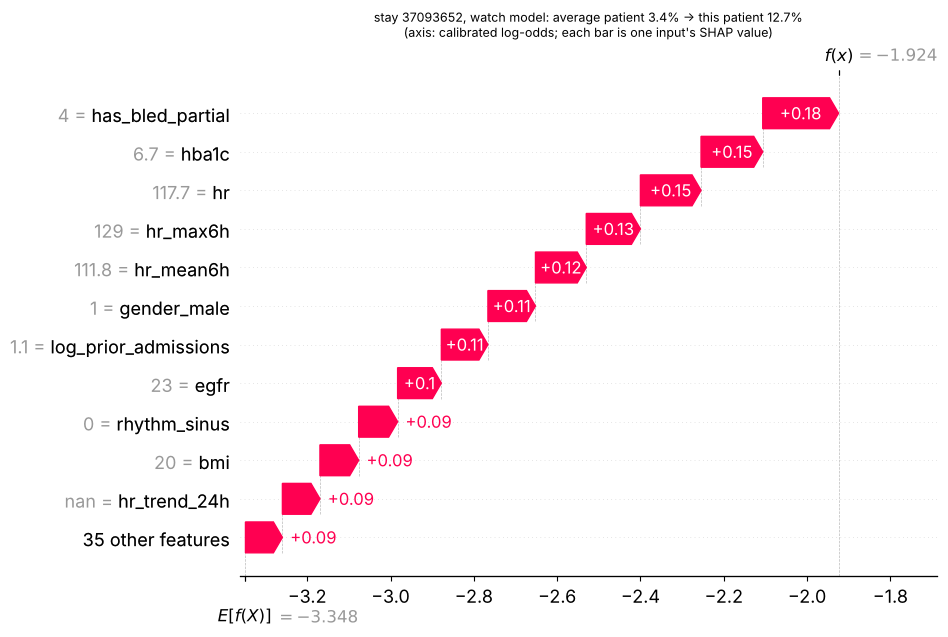

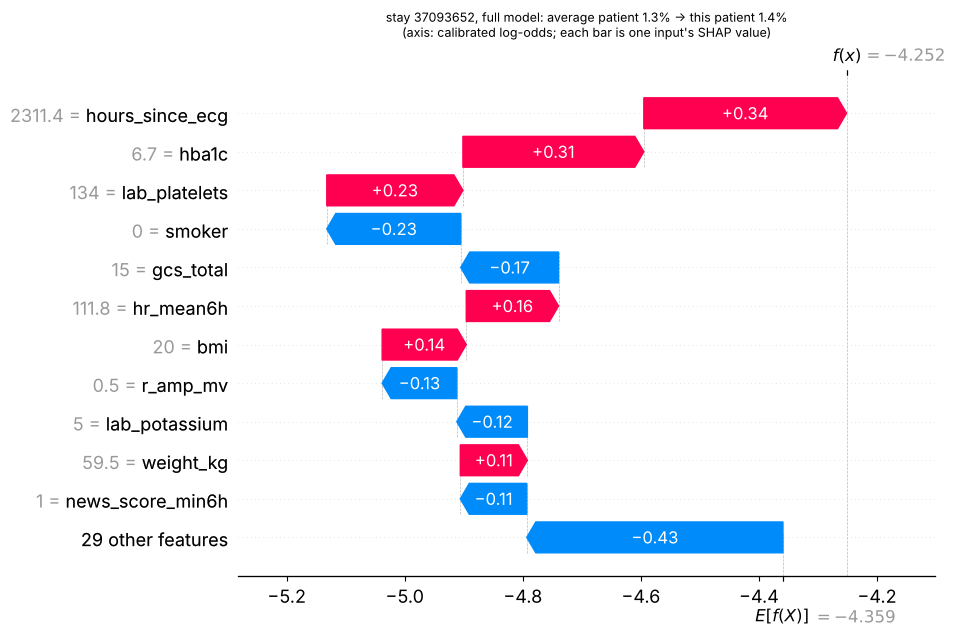

38 waterfall charts saved to charts/shap_charts/waterfalls/


In [19]:
# waterfall per stay and model: from the average patient's log-odds to this patient's log-odds
(CHARTS / "waterfalls").mkdir(exist_ok=True)
def label(f, v):
    if pd.isna(v): return f"{f} = missing"
    return f"{f} = {v:.0f}" if abs(v) >= 10 else f"{f} = {v:.2g}"
def waterfall(s, sid, path, show=False):
    i = TE[TE.stay_id == sid].index[-1]
    head, t = explanation_record(s, i)
    row = TE.loc[i]
    feats = B[s]["features"]
    e = shap.Explanation(values=SV[s, "test"][i] * cal_slope(s), base_values=head["base_log_odds"],
                         data=row[feats].astype(float).round(1).values, feature_names=feats)     # shap shows "value = input"
    plt.figure()
    shap.plots.waterfall(e, max_display=12, show=False)
    fig = plt.gcf(); fig.set_size_inches(9, 6.5)
    plt.title(f"stay {sid}, {s} model: average patient {100 * head['base_probability']:.1f}% → this patient "
              f"{100 * head['output_probability']:.1f}%\n(axis: calibrated log-odds; each bar is one input's SHAP value)", fontsize=9)
    plt.savefig(path, dpi=100, bbox_inches="tight")
    plt.show() if show else plt.close()
for sid in SCORES.stay_id:
    for s in ["watch", "full"]:
        waterfall(s, sid, CHARTS / "waterfalls" / f"stay_{sid}_{s}.png", show=(sid == SCORES.stay_id.iloc[0]))
print(f"{2 * len(SCORES)} waterfall charts saved to charts/shap_charts/waterfalls/")

**Result:** 38 waterfalls saved to `charts/shap_charts/waterfalls/`. The one shown is the highest-risk stay.

## 7 · Personal baseline, temporal tracking, data quality, uncertainty and out-of-range checks

**What this cell does:** the **digital-twin panel**. For heart rate, SpO2 and breathing rate it gives:
- The current reading.
- The patient's own **baseline** (median so far in this stay) and the deviation from it.
- The change over **1, 6 and 24 h**, but only when that much history exists; otherwise it says "no history yet".
- **Coverage** over the last 24 h and **minutes since the last reading**.

It draws a 48 h panel against the baseline and the reference band. Signals the data does not contain are listed and never described.

In [20]:
# personal baseline vs current state, from the hourly series of each stay (only what the data really holds)
(CHARTS / "baseline_panels").mkdir(exist_ok=True)
SIG = {"hr": ("Heart rate", "bpm"), "spo2": ("SpO2", "%"), "rr": ("Breathing rate", "/min")}
NOT_AVAILABLE = ["sleep duration", "steps / activity", "true HRV from the watch (only hourly heart-rate spread is available)",
                 "blood pressure from the watch", "skin temperature"]
def baseline_panel(sid):
    g = TE[TE.stay_id == sid].sort_values("hour").reset_index(drop=True)
    now = g.iloc[-1]; out = {}
    for sig in SIG:
        x = g[sig]
        meas = g[f"{sig}_measured"].fillna(0) > 0
        base = x.expanding().median().iloc[-1]
        def ago(h):
            return float(x.iloc[-1] - x.iloc[-1 - h]) if len(g) > h and pd.notna(x.iloc[-1 - h]) else None
        last = g.hour[meas].max() if meas.any() else pd.NaT
        out[sig] = {"current": None if pd.isna(x.iloc[-1]) else round(float(x.iloc[-1]), 1),
                    "personal_baseline": None if pd.isna(base) else round(float(base), 1),
                    "deviation": None if pd.isna(base) or pd.isna(x.iloc[-1]) else round(float(x.iloc[-1] - base), 1),
                    "change_1h": ago(1), "change_6h": ago(6), "change_24h": ago(24),
                    "coverage_last24h_%": round(100 * meas.iloc[-24:].mean(), 0),
                    "last_reading": None if pd.isna(last) else str(last),
                    "minutes_since_last_reading": None if pd.isna(last) else int((now.hour - last).total_seconds() / 60)}
    return out

def panel_chart(sid, path):
    g = TE[TE.stay_id == sid].sort_values("hour").tail(48)
    hrs = (g.hour - g.hour.iloc[-1]).dt.total_seconds() / 3600
    full = TE[TE.stay_id == sid].sort_values("hour")
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
    for ax, (sig, (name, unit)) in zip(axes, SIG.items()):
        base = full[sig].expanding().median().tail(48)
        ax.plot(hrs, g[sig], color=BLUE, label="hourly reading")
        ax.plot(hrs, base, color=ORANGE, ls="--", label="personal baseline (median so far)")
        if sig in REF:
            _, lo, hi, _ = REF[sig]
            ax.axhspan(lo if lo is not None else ax.get_ylim()[0], hi if hi is not None else ax.get_ylim()[1], color=GREEN, alpha=.08,
                       label=f"reference {REF[sig][0]}")
        ax.set(title=f"{name} ({unit})", xlabel="hours before report"); ax.legend(fontsize=6)
    fig.suptitle(f"stay {sid}: current vs personal baseline (last 48 h)", fontsize=10)
    plt.tight_layout(); plt.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)

BASEL = {}
for sid in SCORES.stay_id:
    BASEL[sid] = baseline_panel(sid)
    panel_chart(sid, CHARTS / "baseline_panels" / f"stay_{sid}.png")
pd.DataFrame([{"stay_id": sid, "signal": sig, **v} for sid, d in BASEL.items() for sig, v in d.items()]).to_csv(
    RES / "personal_baseline_test.csv", index=False)
print(pd.DataFrame(BASEL[SCORES.stay_id.iloc[0]]).T)
print("not available in this data, so never described:", "; ".join(NOT_AVAILABLE))

     current personal_baseline deviation change_1h change_6h change_24h  \
hr     117.7             106.5      11.2      16.9      12.2       None   
spo2    96.3              96.7      -0.4      -0.4      -3.2       None   
rr      17.2              20.4      -3.2      -3.0      -9.8       None   

     coverage_last24h_%         last_reading minutes_since_last_reading  
hr                100.0  2177-03-25 10:00:00                          0  
spo2               92.0  2177-03-25 10:00:00                          0  
rr                100.0  2177-03-25 10:00:00                          0  
not available in this data, so never described: sleep duration; steps / activity; true HRV from the watch (only hourly heart-rate spread is available); blood pressure from the watch; skin temperature


**Result:**
- **Highest-risk stay:** heart rate 118 bpm against a personal baseline of 107 (+11), up 17 bpm in the last hour. It has only 12 h of history, so no 24 h change is given.
- **Not described:** sleep, activity, true HRV, watch BP and skin temperature are not in the data.

Saved `personal_baseline_test.csv` and `charts/shap_charts/baseline_panels/`.

**What this cell does:** **tracks the explanation over time.** For every test hour it computes the SHAP of each reason group, then draws the risk and the 6 largest groups over each stay. It also works out **what changed in the last 6 h**: the risk then and now, and the groups that rose or fell most.

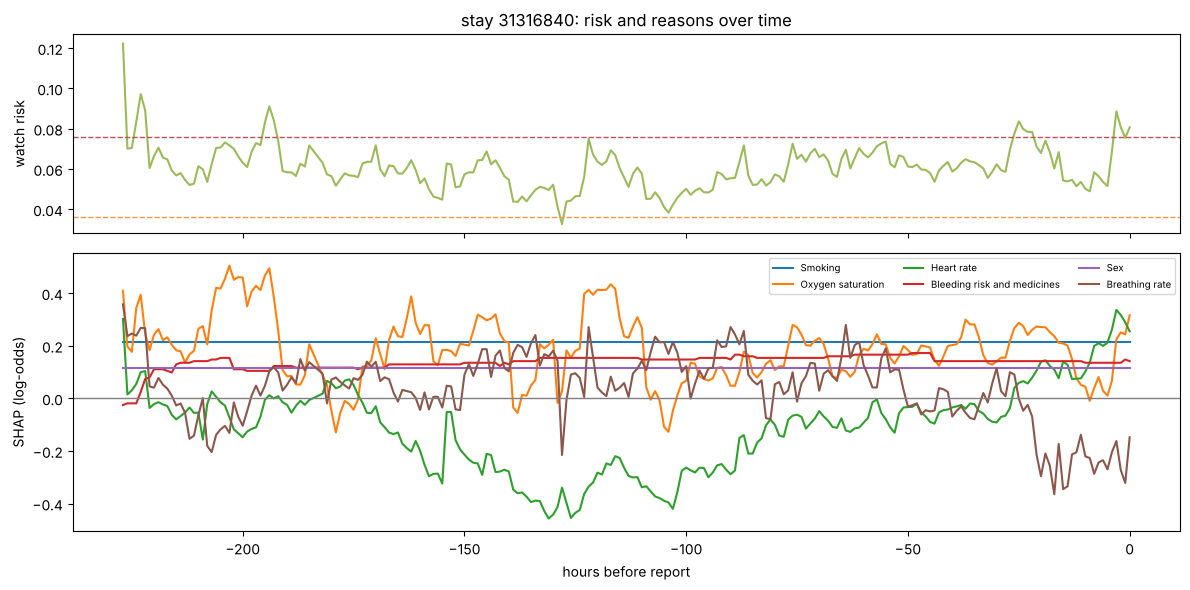

{37093652: {'hours': 6, 'risk_then': 0.11064, 'risk_now': 0.12737, 'biggest_rise': ('Oxygen saturation', 1.1572368366181502), 'biggest_fall': ('Breathing rate', 0.9519529667436876)}, 38229329: {'hours': 6, 'risk_then': 0.10221, 'risk_now': 0.11926, 'biggest_rise': ('Heart rhythm', 1.8135870773934042), 'biggest_fall': ('Oxygen saturation', 0.6317922819021472)}, 31248398: {'hours': 6, 'risk_then': 0.04951, 'risk_now': 0.10359, 'biggest_rise': ('Heart rate', 1.7392320874416112), 'biggest_fall': ('Breathing rate', 0.7082026580236004)}, 31316840: {'hours': 6, 'risk_then': 0.05355, 'risk_now': 0.08065, 'biggest_rise': ('Oxygen saturation', 1.3326252905122082), 'biggest_fall': ('Age', 1.0)}}


In [21]:
# temporal explanation tracking: reason-group SHAP for every hour of every test stay (watch model)
(CHARTS / "timelines").mkdir(exist_ok=True)
feats = B["watch"]["features"]
TG = pd.DataFrame(SV["watch", "test"] * cal_slope("watch"), columns=feats).T.groupby([group_of(f) for f in feats]).sum().T
TG.insert(0, "stay_id", TE.stay_id.values); TG.insert(1, "hour", TE.hour.values); TG.insert(2, "risk_watch", TE.risk_watch.values)
TG.round(4).to_csv(RES / "temporal_group_shap_watch.csv", index=False)

def changed_since(sid, h=6):
    g = TG[TG.stay_id == sid]
    if len(g) <= h: return None
    d = (g.iloc[-1, 3:] - g.iloc[-1 - h, 3:]).astype(float)
    return {"hours": h, "risk_then": float(g.risk_watch.iloc[-1 - h]), "risk_now": float(g.risk_watch.iloc[-1]),
            "biggest_rise": (d.idxmax(), float(np.exp(d.max()))), "biggest_fall": (d.idxmin(), float(np.exp(d.min())))}

def timeline_chart(sid, path, show=False):
    g = TG[TG.stay_id == sid]
    hrs = (pd.to_datetime(g.hour) - pd.to_datetime(g.hour).iloc[-1]).dt.total_seconds() / 3600
    top = g.iloc[:, 3:].abs().mean().nlargest(6).index
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
    a1.plot(hrs, g.risk_watch, color=GREEN); a1.axhline(TIERS["watch"]["high"], color=RED, ls="--", lw=1)
    a1.axhline(TIERS["watch"]["moderate"], color=ORANGE, ls="--", lw=1); a1.set(ylabel="watch risk", title=f"stay {sid}: risk and reasons over time")
    for c in top:
        a2.plot(hrs, g[c], label=c)
    a2.axhline(0, color=GREY, lw=1); a2.set(xlabel="hours before report", ylabel="SHAP (log-odds)"); a2.legend(fontsize=7, ncol=3)
    plt.tight_layout(); plt.savefig(path, dpi=100, bbox_inches="tight")
    plt.show() if show else plt.close(fig)
for sid in SCORES.stay_id:
    timeline_chart(sid, CHARTS / "timelines" / f"stay_{sid}.png", show=(sid == 31316840))
print({sid: changed_since(sid) for sid in SCORES.stay_id[:4]})

**Result:** in stay 31316840 the risk rose from 5.4% to 8.1% over the last 6 h, mostly because oxygen saturation fell (×1.33). In stay 31248398 it doubled from 5.0% to 10.4%, driven by heart rate (×1.74). Saved `temporal_group_shap_watch.csv` and `charts/shap_charts/timelines/`.

**What this cell does:**
- **Data quality:** missing inputs, stale signals (no reading for over 2 h) and low coverage (under 50% of the last 24 h).
- **Out-of-range check:** flags inputs outside the range of 99% of training hours, a simple, transparent out-of-distribution check.
- **Uncertainty:** refits the watch model on 100 resamples of the training patients, to give a 90% range for each patient's risk.

Saves `data_quality_test.csv` and `risk_uncertainty_watch.csv`.

In [22]:
# data quality, out-of-range inputs and model uncertainty at report time
LO, HI = TR.quantile(0.005, numeric_only=True), TR.quantile(0.995, numeric_only=True)
def ood(s, row):
    # inputs outside the range seen in 99% of training hours: a simple, transparent out-of-distribution check
    return [f for f in B[s]["features"] if pd.notna(row[f]) and (row[f] < LO[f] or row[f] > HI[f])]

def missing_inputs(s, row):
    return [f for f in B[s]["features"] if pd.isna(row[f])]

# uncertainty: refit the watch logistic regression on 100 patient-level bootstrap samples of the train patients
from sklearn.base import clone
rng = np.random.default_rng(SEED)
pats = TR.subject_id.unique(); feats = B["watch"]["features"]
rep = TE.groupby("stay_id").tail(1)
boot = []
for _ in range(100):
    pick = rng.choice(pats, len(pats), replace=True)
    d = pd.concat([TR[TR.subject_id == p] for p in pick])
    if d.y_24h.nunique() < 2: continue
    m = clone(B["watch"]["estimator"]).fit(d[feats].astype(float), d.y_24h)
    boot.append(m.predict_proba(rep[feats].astype(float))[:, 1])
boot = np.array(boot)
UNC = pd.DataFrame({"stay_id": rep.stay_id.values, "risk_watch": rep.risk_watch.values,
                    "p05": np.percentile(boot, 5, axis=0), "p95": np.percentile(boot, 95, axis=0)})
UNC["tier_low_end"] = [tier("watch", p) for p in UNC.p05]; UNC["tier_high_end"] = [tier("watch", p) for p in UNC.p95]
UNC = UNC.set_index("stay_id")

DQ = {}
for sid in SCORES.stay_id:
    row = TE.loc[TE[TE.stay_id == sid].index[-1]]
    b = BASEL[sid]
    stale = [SIG[k][0] for k, v in b.items() if v["minutes_since_last_reading"] is None or v["minutes_since_last_reading"] > 120]
    low_cov = [SIG[k][0] for k, v in b.items() if v["coverage_last24h_%"] < 50]
    DQ[sid] = {"missing_watch_inputs": missing_inputs("watch", row), "missing_full_inputs": missing_inputs("full", row),
               "out_of_range_watch": ood("watch", row), "out_of_range_full": ood("full", row),
               "stale_signals": stale, "low_coverage_signals": low_cov,
               "risk_90pct_interval": [round(float(UNC.loc[sid, "p05"]), 4), round(float(UNC.loc[sid, "p95"]), 4)],
               "tier_could_change": bool(UNC.loc[sid, "tier_low_end"] != UNC.loc[sid, "tier_high_end"])}
    DQ[sid]["status"] = ("STALE" if stale else "CHECK" if (low_cov or len(DQ[sid]["out_of_range_watch"]) > 2) else "OK")
pd.DataFrame(DQ).T.to_csv(RES / "data_quality_test.csv")
UNC.round(4).to_csv(RES / "risk_uncertainty_watch.csv")
print(f"{len(boot)} bootstrap refits")
print(pd.DataFrame(DQ).T[["status", "stale_signals", "low_coverage_signals", "out_of_range_watch", "risk_90pct_interval", "tier_could_change"]]
      .to_string())

100 bootstrap refits
         status                       stale_signals low_coverage_signals                                        out_of_range_watch risk_90pct_interval tier_could_change
37093652     OK                                  []                   []                                                        []    [0.0228, 0.2928]              True
38229329  STALE  [Heart rate, SpO2, Breathing rate]                   []                                                 [non_hdl]    [0.0304, 0.2571]              True
31248398  STALE                              [SpO2]                   []  [hr_delta6h, rr_lag1, non_hdl, rr_max6h, hr_vs_baseline]    [0.0153, 0.2412]              True
31316840     OK                                  []                   []                                                        []    [0.0181, 0.1955]              True
39635619     OK                                  []                   []                                        [hba1c, height_in]    

**Result:**
- **Data quality:** 17 stays are OK. **2 are STALE**: no watch reading for over 2 h at report time, so their reports say to repeat the readings first.
- **Out of range:** a few profile values (for example non-HDL, HbA1c) and, in one stay, 5 vital-sign trends are outside the training range.
- **Uncertainty is large:** for example 8.1% has a range of 1.8-19.6%, and 18 of 19 stays' ranges cross a tier boundary. This is the honest cost of 16 training events.

**What this cell does:** a **prototype what-if simulator**. It re-runs the saved watch model with one input changed:
- heart rate 10 bpm lower (all heart-rate inputs together);
- SpO2 2 points higher;
- not smoking.

It also finds a **counterfactual**: the smallest heart-rate drop (up to 30 bpm) that moves the tier down a step. These are **simulations of the model, not causal effects or treatment advice**. Saves `what_if_watch_prototype.csv`.

In [23]:
# what-if simulator and counterfactual (PROTOTYPE): re-run the same saved watch model on edited inputs.
# These are simulations of the model, not treatment advice and not predictions of what would really happen.
HR_F = ["hr", "hr_lag1", "hr_mean6h", "hr_max6h", "hr_vs_baseline"]
SPO2_F = ["spo2", "spo2_lag1", "spo2_mean6h", "spo2_min6h", "spo2_max6h"]
def scenario(row, name):
    r = row.copy()
    if name == "heart rate 10 bpm lower":
        for f in HR_F: r[f] = r[f] - 10 if pd.notna(r[f]) else r[f]
    elif name == "SpO2 2 points higher":
        for f in SPO2_F: r[f] = min(r[f] + 2, 100) if pd.notna(r[f]) else r[f]
    elif name == "not smoking":
        r["smoker"] = 0
    return r
def risk_of(r, s="watch"):
    return float(predict(s, pd.DataFrame([r]))[0])

WHATIF = []
for sid in SCORES.stay_id:
    row = TE.loc[TE[TE.stay_id == sid].index[-1]]
    p0 = risk_of(row)
    for name in ["heart rate 10 bpm lower", "SpO2 2 points higher", "not smoking"]:
        p1 = risk_of(scenario(row, name))
        WHATIF.append({"stay_id": sid, "scenario": name, "risk_before": round(p0, 4), "risk_after": round(p1, 4),
                       "tier_before": tier("watch", p0), "tier_after": tier("watch", p1)})
    # counterfactual: the smallest consistent heart-rate shift (1-30 bpm down) that moves the tier one step down
    cf = None
    if tier("watch", p0) != "Low":
        for d in range(1, 31):
            r = row.copy()
            for f in HR_F: r[f] = r[f] - d if pd.notna(r[f]) else r[f]
            if tier("watch", risk_of(r)) != tier("watch", p0):
                cf = d; break
    WHATIF.append({"stay_id": sid, "scenario": "counterfactual: heart-rate drop needed to lower the tier",
                   "risk_before": round(p0, 4), "risk_after": np.nan, "tier_before": tier("watch", p0),
                   "tier_after": (f"{cf} bpm lower" if cf else "not reached within 30 bpm") if tier("watch", p0) != "Low" else "already Low"})
WI = pd.DataFrame(WHATIF)
WI.to_csv(RES / "what_if_watch_prototype.csv", index=False)
print("SIMULATION ONLY: the model's response to edited inputs, not a causal effect or a treatment recommendation")
print(WI[WI.stay_id.isin(SCORES.stay_id[:3])].to_string(index=False))

SIMULATION ONLY: the model's response to edited inputs, not a causal effect or a treatment recommendation
 stay_id                                                 scenario  risk_before  risk_after tier_before   tier_after
37093652                                  heart rate 10 bpm lower       0.1274      0.1062        High         High
37093652                                     SpO2 2 points higher       0.1274      0.1099        High         High
37093652                                              not smoking       0.1274      0.1274        High         High
37093652 counterfactual: heart-rate drop needed to lower the tier       0.1274         NaN        High 29 bpm lower
38229329                                  heart rate 10 bpm lower       0.1193      0.0993        High         High
38229329                                     SpO2 2 points higher       0.1193      0.1055        High         High
38229329                                              not smoking       0.1193    

**Result:**
- **What-if:** for the top stay, 10 bpm lower heart rate moves the risk from 12.7% to 10.6%, and SpO2 +2 moves it to 11.0%. Not smoking changes nothing there, because the patient already does not smoke.
- **Counterfactual:** the heart-rate drop needed to lower the tier ranges from 2 to 29 bpm across stays. 6 stays are already Low.

**What this cell does:** the **calibration panel**. It shows what the predicted probability means, and how well it matched the observed event rate on the test patients, using the metrics saved in the model bundles. Saves `calibration_panel.json`.

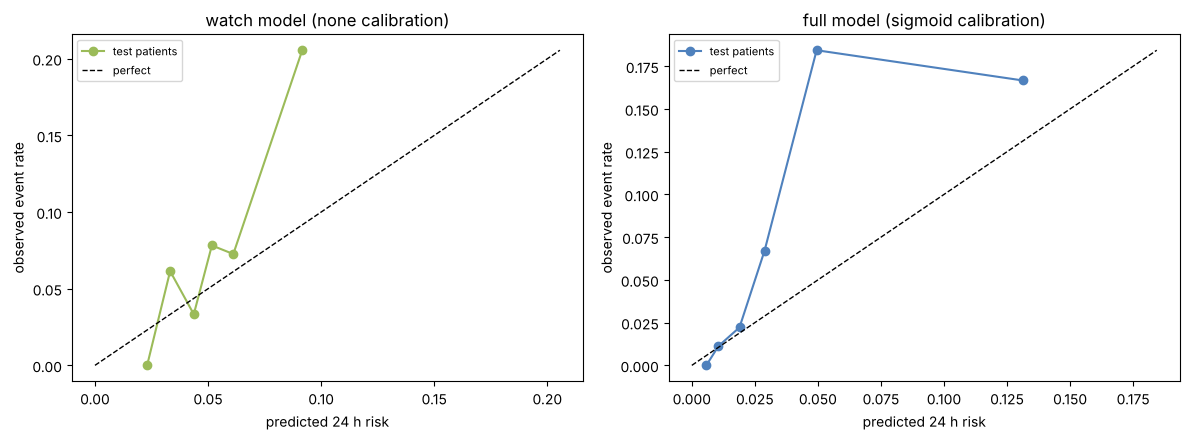

A risk of 10% means that, among patients the model scored at about 10%, about 1 in 10 had the event within 24 h in the data it was checked on. It is not a diagnosis, and it was checked on only 15 test patients (4 events).
{
 "watch": {
  "calibration_slope": 1.714,
  "calibration_intercept": 0.427,
  "mean_predicted": 0.0508,
  "prevalence": 0.0752,
  "Brier": 0.0677,
  "AUROC": 0.7321,
  "AUPRC": 0.1928
 },
 "full": {
  "calibration_slope": 0.922,
  "calibration_intercept": 0.708,
  "mean_predicted": 0.0408,
  "prevalence": 0.0752,
  "Brier": 0.068,
  "AUROC": 0.8004,
  "AUPRC": 0.1876
 }
}


In [24]:
# calibration panel: what the predicted probability means, and how well it held on cross-validation and test
from sklearn.calibration import calibration_curve
CALP = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, s in zip(axes, ["watch", "full"]):
    tm = B[s]["test_metrics"]
    pt, pp = calibration_curve(TE.y_24h, TE[f"risk_{s}"], n_bins=6, strategy="quantile")
    ax.plot(pp, pt, "o-", color=GREEN if s == "watch" else BLUE, label="test patients")
    ax.plot([0, max(pp.max(), pt.max())], [0, max(pp.max(), pt.max())], "k--", lw=1, label="perfect")
    ax.set(xlabel="predicted 24 h risk", ylabel="observed event rate", title=f"{s} model ({B[s]['calibrator'].method} calibration)")
    ax.legend(fontsize=8)
    CALP[s] = {k: tm.get(k) for k in ["calibration_slope", "calibration_intercept", "mean_predicted", "prevalence", "Brier", "AUROC", "AUPRC"]}
savefig("13_calibration_panel")
CAL_MEANING = ("A risk of 10% means that, among patients the model scored at about 10%, about 1 in 10 had the event within 24 h in "
               "the data it was checked on. It is not a diagnosis, and it was checked on only 15 test patients (4 events).")
json.dump({"meaning": CAL_MEANING, **CALP}, open(RES / "calibration_panel.json", "w"), indent=1, default=float)
print(CAL_MEANING); print(json.dumps(CALP, indent=1, default=float))

**Result:** the full model is well calibrated on test (slope 0.92). The watch model's slope is 1.71, so its risks are too cautious at the extremes. Both under-predict on average (5.1% and 4.1% predicted vs 7.5% observed), because the test patients had more events than training. Saved `13_calibration_panel.png`.

## 8 · SAR doctor reports (Situation, Assessment, Recommendation), exports and audit trail

**What this cell does:** writes the **SAR doctor report** for every test stay, from structured facts with a deterministic template:
- **One-line clinical summary.**
- **S · Situation:** the risk, tier, cut-offs, target and horizon; the full-model second opinion; and a current-vs-baseline table with the time of each last reading and its reference range.
- **A · Assessment:** the top 3 reasons by absolute SHAP, with values, reference ranges and direction; what changed in 6 h; the uncertainty range; the full model's reasons; and the limits of the explanation.
- **R · Recommendation:** anchored on the validated **NEWS2 escalation protocol** (RCP 2017), with a data-check step first when readings are stale. It never suggests treatment.
- **Extra sections:** data-quality warnings, what the probability means, and a collapsible **technical section** for the ML team (log-odds, feature SHAP table, provenance, model and data md5).

Each report is saved as **.md, .html (all charts embedded) and .pdf**. A JSON **audit record** is written for each, holding inputs, SHAP, model version and md5, template version and a report hash, plus `audit_log.csv`.

In [25]:
import hashlib, base64, datetime as dt
from matplotlib.backends.backend_pdf import PdfPages
import textwrap
TEMPLATE_VERSION = "SAR-1.0 (deterministic template)"
md5 = lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest()
MODEL_FILES = {s: MODELS / f"cardiotwin_{s}_24h.pkl" for s in B}
PROV = {"model_md5": {s: md5(p) for s, p in MODEL_FILES.items()}, "data_md5": md5(FEAT / "model_final.csv"),
        "model_version": {s: B[s]["version"] for s in B}, "libraries": LIBS}

def group_reasons(s, i, n=3):
    row = TE.loc[i]
    gsum, g = grouped(s, SV[s, "test"][i])
    top = gsum.reindex(gsum.abs().sort_values(ascending=False).index)[:n]       # top 3 by absolute contribution
    out = []
    for name, x in top.items():
        members = [f for f in g.index if group_of(f) == name]
        shown = sorted([f for f in members if np.sign(g[f]) == np.sign(x)] or members, key=lambda f: -abs(g[f]))[:2]
        out.append({"group": name, "shap_log_odds": float(x), "odds_multiplier": float(np.exp(x)), "direction": effect(x)[0],
                    "warning": against_expectation(name, x, row),
                    "facts": [{"feature": f, "value": None if pd.isna(row[f]) else float(row[f]), "text": describe(f, row[f]),
                               "reference": REF.get(f, ("",))[0], "vs_reference": ref_flag(f, row[f]),
                               "shap_log_odds": float(g[f]), "provenance": provenance(f, row[f])} for f in shown]})
    return out

def recommendation(t, dq):
    # anchored on the NEWS2 escalation protocol (RCP 2017), which is validated; the model itself is not
    r = {"High": ["Prompt bedside review by a clinician, with a full set of observations (BP, temperature, consciousness, SpO2, breathing, heart rate).",
                  "Score NEWS2 at the bedside: 5-6 (or any single parameter scoring 3) needs an urgent ward-based response; 7 or more needs an emergency response, per local escalation policy."],
         "Moderate": ["Increase observation frequency and repeat a full set of observations, scoring NEWS2.",
                      "Escalate per local policy if NEWS2 is 5 or more, or if the trend keeps rising."],
         "Low": ["Continue routine monitoring at the usual frequency."]}[t]
    if dq["status"] != "OK":
        r = ["Check the watch fit and repeat the readings first: the data is " + dq["status"].lower() + ", so the score may be unreliable."] + r
    return r + ["This score supports, and never replaces, clinical judgement. It suggests no treatment."]

def sar(sid):
    i = TE[TE.stay_id == sid].index[-1]; row = TE.loc[i]
    srow = SCORES.set_index("stay_id").loc[sid]
    hw, tw = explanation_record("watch", i); hf, _ = explanation_record("full", i)
    rs, rf = group_reasons("watch", i), group_reasons("full", i)
    dq, b, ch = DQ[sid], BASEL[sid], changed_since(sid)
    t = tier("watch", hw["output_probability"])
    lo, hi = dq["risk_90pct_interval"]
    one = (f"{t} risk ({100 * hw['output_probability']:.1f}%, model range {100 * lo:.1f}-{100 * hi:.1f}%) of deterioration within 24 h, "
           f"driven mainly by {', '.join(r['group'].lower() for r in rs if r['shap_log_odds'] > 0) or 'no strong factor'}; data {dq['status']}.")
    return {"stay_id": int(sid), "subject_id": int(row.subject_id), "report_time": str(row.hour), "one_line": one, "tier": t,
            "situation": {"risk": hw["output_probability"], "tier": t, "cutoffs": TIERS["watch"],
                          "target": "first vasopressor start, lactate >= 4 mmol/L or in-hospital death", "horizon_h": 24,
                          "output_space": "probability from calibrated log-odds", "average_patient_risk": hw["base_probability"],
                          "full_model_risk": hf["output_probability"], "full_model_tier": tier("full", hf["output_probability"]),
                          "current": b, "monitored_hours": int(srow.hours_monitored)},
            "assessment": {"top3": rs, "full_model_top3": rf, "changed_6h": ch, "uncertainty_90": [lo, hi],
                           "tier_could_change": bool(dq["tier_could_change"])},
            "recommendation": recommendation(t, dq), "data_quality": dq,
            "technical": {"watch": hw, "full": hf, "top_features": tw.head(15).round(4).to_dict("records")},
            "calibration": CALP["watch"], "outcome_note": ("an event did follow within 24 h" if srow.event_within_24h_of_report
                                                           else "the event came later in this stay" if srow.stay_has_event else "no event in this stay")}

def fmt_change(v, unit):
    return "no history yet" if v is None else f"{v:+.0f} {unit}"

def to_markdown(R, img_prefix="../../charts/shap_charts"):
    S, A = R["situation"], R["assessment"]; sid = R["stay_id"]
    L = [f"# CardioTwin SAR report · patient {R['subject_id']} · stay {sid}", "",
         f"**One-line summary:** {R['one_line']}", "",
         f"*Report time {R['report_time']} (end of the last monitored hour) · watch model {PROV['model_version']['watch']} · "
         f"template {TEMPLATE_VERSION}*", "",
         "## S · Situation", "",
         f"- **Model-estimated risk:** {100 * S['risk']:.1f}% (**{S['tier']}**). Moderate starts at {100 * S['cutoffs']['moderate']:.1f}% "
         f"and High at {100 * S['cutoffs']['high']:.1f}%. An average patient's risk is {100 * S['average_patient_risk']:.1f}%.",
         f"- **Target:** {S['target']}, within the next {S['horizon_h']} h.",
         f"- **Full ICU reference model:** {100 * S['full_model_risk']:.1f}% ({S['full_model_tier']}).", "",
         "| Signal | Current | Personal baseline | Change 1 h / 6 h / 24 h | Reference | Last reading | Coverage 24 h |", "|---|---|---|---|---|---|---|"]
    for sig, (name, unit) in SIG.items():
        v = S["current"][sig]
        L.append(f"| {name} | {v['current']} {unit} | {v['personal_baseline']} {unit} | {fmt_change(v['change_1h'], unit)} / "
                 f"{fmt_change(v['change_6h'], unit)} / {fmt_change(v['change_24h'], unit)} | {REF[sig][0]} | {v['last_reading']} | "
                 f"{v['coverage_last24h_%']:.0f}% |")
    L += ["", f"Not available in this data, so not described: {', '.join(NOT_AVAILABLE)}.", "",
          f"![patient card]({img_prefix}/patient_cards/stay_{sid}.png)", "",
          "## A · Assessment", "", "**Top 3 contributors (largest absolute SHAP, by reason group):**", ""]
    for n, r in enumerate(A["top3"], 1):
        facts = "; ".join(f"{f['text']}" + (f" [reference {f['reference']}, {f['vs_reference']}]" if f["reference"] else "") for f in r["facts"])
        L.append(f"{n}. **{r['group']}** {r['direction']} the risk (odds ×{r['odds_multiplier']:.2f}): {facts}."
                 + (" ⚠ This direction goes against usual clinical expectation; do not rely on it." if r["warning"] else ""))
    ch = A["changed_6h"]
    L += ["", "- **Over the last 6 h:** " + ("not enough history yet." if ch is None else
          f"risk {100 * ch['risk_then']:.1f}% → {100 * ch['risk_now']:.1f}%; the biggest rise came from {ch['biggest_rise'][0].lower()} "
          f"(×{ch['biggest_rise'][1]:.2f})" + (f", the biggest fall from {ch['biggest_fall'][0].lower()} (×{ch['biggest_fall'][1]:.2f})."
                                                if ch['biggest_fall'][1] < 0.99 else "; no reason group lowered it noticeably.")),
          f"- **Model uncertainty:** 90% of models refit on resampled training patients give {100 * A['uncertainty_90'][0]:.1f}-"
          f"{100 * A['uncertainty_90'][1]:.1f}%" + (", so the tier could differ." if A["tier_could_change"] else ", within the same tier."),
          f"- **Full model's top reasons:** {', '.join(r['group'] for r in A['full_model_top3'])}.",
          "- **Limits of this explanation:** SHAP shows what the model relied on, not causes. The model was trained on 59 ICU patients "
          "with 16 events, so individual reasons can be unstable.", "",
          f"![waterfall]({img_prefix}/waterfalls/stay_{sid}_watch.png)", "",
          f"![baseline]({img_prefix}/baseline_panels/stay_{sid}.png)", "",
          f"![timeline]({img_prefix}/timelines/stay_{sid}.png)", "",
          "## R · Recommendation (for clinician review)", ""] + [f"- {x}" for x in R["recommendation"]]
    dq = R["data_quality"]
    L += ["", "## Data quality and warnings", "",
          f"- **Status:** {dq['status']}.",
          f"- **Stale signals (no reading for over 2 h):** {', '.join(dq['stale_signals']) or 'none'}.",
          f"- **Low coverage (under 50% of the last 24 h):** {', '.join(dq['low_coverage_signals']) or 'none'}.",
          f"- **Missing watch-model inputs (filled by the model):** {', '.join(dq['missing_watch_inputs']) or 'none'}.",
          f"- **Inputs outside the training range:** {', '.join(dq['out_of_range_watch']) or 'none'}.", "",
          "## What the probability means", "", CAL_MEANING,
          f" On the test patients the watch model's calibration slope was {R['calibration']['calibration_slope']} (1 is perfect) and its "
          f"mean predicted risk {100 * R['calibration']['mean_predicted']:.1f}% vs {100 * R['calibration']['prevalence']:.1f}% observed.", "",
          "<details><summary>Technical details (for the ML team)</summary>", "",
          f"Output space: calibrated log-odds. Base (average patient) log-odds {R['technical']['watch']['base_log_odds']}, "
          f"this patient {R['technical']['watch']['output_log_odds']} → probability {R['technical']['watch']['output_probability']}. "
          "SHAP: exact linear SHAP (interventional, train background), missing-value flags folded into their input. "
          "\"Explanation share\" is each input's share of the total |SHAP|, an explanation metric and not a risk percentage.", "",
          "| Input | Value | Unit | Provenance | SHAP (log-odds) | Odds × | Explanation share |", "|---|---|---|---|---|---|---|"]
    for f in R["technical"]["top_features"]:
        L.append(f"| {f['feature']} | {f['value']} | {f['unit']} | {f['provenance']} | {f['shap_log_odds']:+.3f} | {f['odds_multiplier']:.2f} | "
                 f"{f['explanation_share_%']:.1f}% |")
    L += ["", f"Model files md5: {PROV['model_md5']}; data md5: {PROV['data_md5']}.", "", "</details>", "",
          f"*Retrospective test: {R['outcome_note']}.*", "", "---",
          "*Research prototype (MIMIC-IV demo, 59 ICU training patients). Not a medical device. It does not diagnose and does not suggest treatment.*", ""]
    return "\n".join(L)

def to_html(R):
    body = to_markdown(R)
    import subprocess
    html = None
    try:
        html = subprocess.run(["pandoc", "-f", "markdown", "-t", "html"], input=body, capture_output=True, text=True, check=True).stdout
    except Exception:
        html = "<pre>" + body.replace("<", "&lt;") + "</pre>"     # deterministic fallback without pandoc
    def embed(m):
        p = (REPORTS / m.group(1)).resolve()
        return f'src="data:image/png;base64,{base64.b64encode(p.read_bytes()).decode()}"' if p.exists() else m.group(0)
    html = re.sub(r'src="([^"]+\.png)"', embed, html)
    css = "body{font-family:Arial,sans-serif;max-width:980px;margin:24px auto;padding:0 16px;color:#222}table{border-collapse:collapse;font-size:13px}td,th{border:1px solid #ccc;padding:4px 6px}img{max-width:100%}h2{border-bottom:2px solid #4f81bd}"
    return f"<!doctype html><html><head><meta charset='utf-8'><title>CardioTwin SAR {R['stay_id']}</title><style>{css}</style></head><body>{html}</body></html>"

def to_pdf(R, path):
    # best: print the HTML report with a headless Chrome/Chromium if one is installed; fallback: a plain matplotlib PDF
    import shutil, subprocess, glob
    html_path = REPORTS / f"stay_{R['stay_id']}.html"
    chrome = next((c for c in [os.environ.get("CHROME_PATH"), shutil.which("chromium"), shutil.which("google-chrome"),
                               shutil.which("chrome"), *glob.glob("/opt/pw-browsers/chromium-*/chrome-linux/chrome"),
                               r"C:\Program Files\Google\Chrome\Application\chrome.exe",
                               r"C:\Program Files (x86)\Microsoft\Edge\Application\msedge.exe"] if c and Path(c).exists()), None)
    if chrome and html_path.exists():
        try:
            subprocess.run([chrome, "--headless", "--no-sandbox", "--disable-gpu", "--no-pdf-header-footer",
                            f"--print-to-pdf={Path(path).resolve()}", html_path.resolve().as_uri()],
                           capture_output=True, timeout=120, check=True)
            if Path(path).exists() and Path(path).stat().st_size > 10000:
                return "browser"
        except Exception:
            pass
    sid = R["stay_id"]
    text = to_markdown(R).split("<details>")[0]
    text = re.sub(r"!\[[^\]]*\]\([^)]*\)", "", text).replace("**", "").replace("|---", "")
    lines = []
    for ln in text.splitlines():
        lines += textwrap.wrap(ln, 120) or [""]
    with PdfPages(path) as pdf:
        for k in range(0, len(lines), 58):
            fig = plt.figure(figsize=(8.27, 11.69)); fig.text(0.05, 0.97, "\n".join(lines[k:k + 58]), va="top", fontsize=7, family="monospace")
            pdf.savefig(fig); plt.close(fig)
        for img in [f"patient_cards/stay_{sid}.png", f"waterfalls/stay_{sid}_watch.png", f"baseline_panels/stay_{sid}.png", f"timelines/stay_{sid}.png"]:
            fig = plt.figure(figsize=(11.69, 8.27)); ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(plt.imread(CHARTS / img)); ax.axis("off")
            pdf.savefig(fig); plt.close(fig)
    return "matplotlib"

(RES / "audit").mkdir(exist_ok=True)
AUDIT, ALL = [], []
for sid in SCORES.stay_id:
    patient_card(sid, CHARTS / "patient_cards" / f"stay_{sid}.png")
    R = sar(sid)
    mdtxt = to_markdown(R)
    (REPORTS / f"stay_{sid}.md").write_text(mdtxt, encoding="utf-8")
    (REPORTS / f"stay_{sid}.html").write_text(to_html(R), encoding="utf-8")
    PDF_ENGINE = to_pdf(R, REPORTS / f"stay_{sid}.pdf")
    ALL.append(mdtxt)
    rec_id = hashlib.sha256((str(sid) + R["report_time"] + PROV["model_md5"]["watch"] + TEMPLATE_VERSION).encode()).hexdigest()[:16]
    i = TE[TE.stay_id == sid].index[-1]
    audit = {"record_id": rec_id, "created_at": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
             "prediction_time": R["report_time"], "stay_id": int(sid), "model_version": PROV["model_version"],
             "model_md5": PROV["model_md5"], "data_md5": PROV["data_md5"], "template_version": TEMPLATE_VERSION,
             "libraries": LIBS, "inputs": {f: (None if pd.isna(TE.loc[i, f]) else float(TE.loc[i, f])) for f in B["watch"]["features"]},
             "shap_watch_log_odds": dict(zip(B["watch"]["features"], np.round(SV["watch", "test"][i] * cal_slope("watch"), 6).tolist())),
             "report": R, "report_sha256": hashlib.sha256(mdtxt.encode()).hexdigest()}
    json.dump(audit, open(RES / "audit" / f"stay_{sid}.json", "w"), indent=1, default=str)
    AUDIT.append({k: audit[k] for k in ["record_id", "created_at", "prediction_time", "stay_id", "template_version", "report_sha256"]}
                 | {"watch_model_md5": PROV["model_md5"]["watch"], "data_md5": PROV["data_md5"], "risk": R["situation"]["risk"], "tier": R["tier"]})
(REPORTS / "ALL_DOCTOR_REPORTS.md").write_text("\n\n".join(ALL), encoding="utf-8")
pd.DataFrame(AUDIT).to_csv(RES / "audit" / "audit_log.csv", index=False)
print(f"{len(SCORES)} SAR reports written (.md, .html with embedded charts, .pdf via {PDF_ENGINE}), plus audit records in results/explanations/audit/")
print("\n" + "=" * 100 + "\n" + to_markdown(sar(31316840)).split("<details>")[0])

19 SAR reports written (.md, .html with embedded charts, .pdf via browser), plus audit records in results/explanations/audit/

# CardioTwin SAR report · patient 10005817 · stay 31316840

**One-line summary:** High risk (8.1%, model range 1.8-19.6%) of deterioration within 24 h, driven mainly by oxygen saturation, heart rate, smoking; data OK.

*Report time 2135-01-13 09:00:00 (end of the last monitored hour) · watch model 1.0.0+2026-10-18 · template SAR-1.0 (deterministic template)*

## S · Situation

- **Model-estimated risk:** 8.1% (**High**). Moderate starts at 3.6% and High at 7.6%. An average patient's risk is 3.4%.
- **Target:** first vasopressor start, lactate >= 4 mmol/L or in-hospital death, within the next 24 h.
- **Full ICU reference model:** 20.6% (High).

| Signal | Current | Personal baseline | Change 1 h / 6 h / 24 h | Reference | Last reading | Coverage 24 h |
|---|---|---|---|---|---|---|
| Heart rate | 98.0 bpm | 82.0 bpm | -4 bpm / +0 bpm / +6 bpm | 60-100 bpm | 2135

**Result:** 19 SAR reports in 3 formats, 19 audit records and an audit log. The printout shows stay 31316840: **High (8.1%)**, driven by low oxygen (90%, below the 95-100% range), heart rate (102 bpm average) and smoking. SpO2 fell 7 points in 6 h. That patient deteriorated within 24 h.

**What this cell does:** shows the patient card, waterfall and baseline panel for stay 31316840, the pieces each report combines into a dashboard-style page.

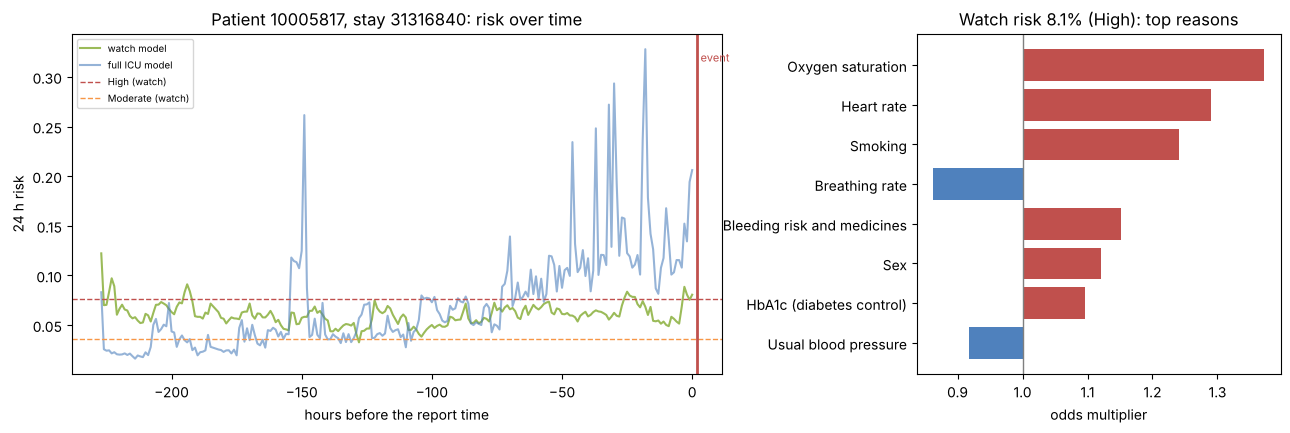

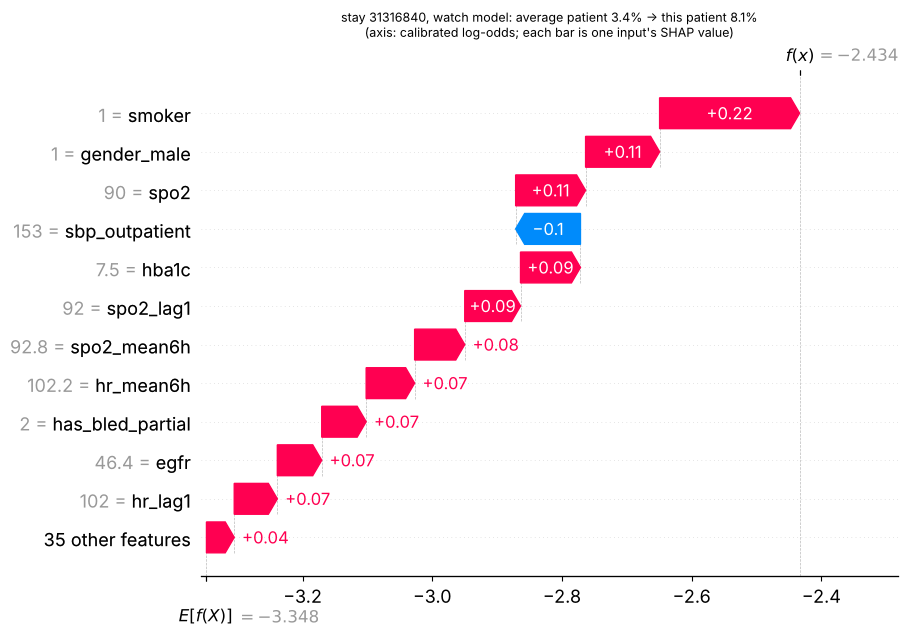

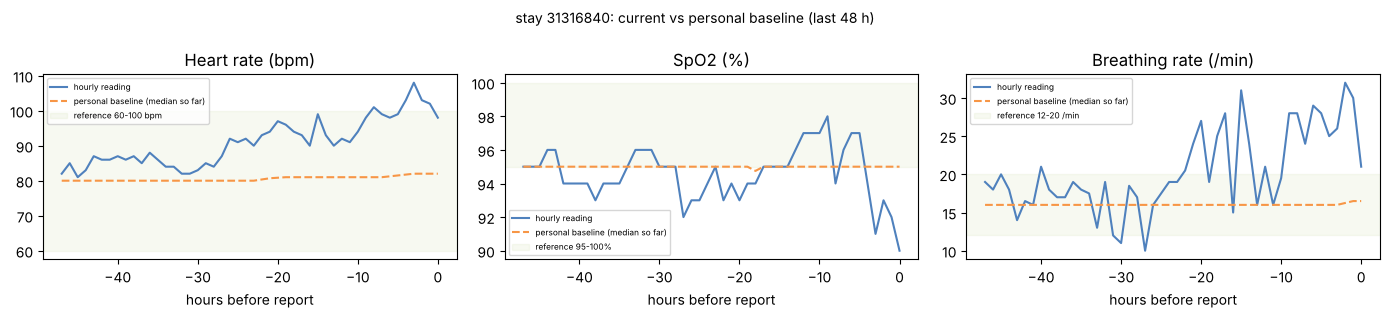

In [26]:
# show the dashboard-style pieces for one stay with an event
from IPython.display import Image, display
for img in ["patient_cards/stay_31316840.png", "waterfalls/stay_31316840_watch.png", "baseline_panels/stay_31316840.png"]:
    display(Image(filename=str(CHARTS / img)))

**Result:** see the three charts below.

## 9 · Checks: consistency, stability and reproducibility of the explanations

**What this cell does:** checks the explanations:
1. **Consistency:** every reason's direction word, odds multiplier and quoted values match the SHAP numbers and the data, and the top-3 order matches SHAP.
2. **Stability:** small, plausible nudges (heart rate ±2 bpm, SpO2 ±1, breathing ±1) should not reshuffle the top 3 reasons.
3. **Reproducibility:** a report rebuilt from its audit record must match the saved hash.

Saves `consistency_checks.csv`, `explanation_stability.csv` and `explanation_checks.json`.

In [27]:
checks, rows = {}, []
# 1. consistency: every statement in every report agrees with the numbers behind it
for sid in SCORES.stay_id:
    R = json.load(open(RES / "audit" / f"stay_{sid}.json"))["report"]
    i = TE[TE.stay_id == sid].index[-1]
    for r in R["assessment"]["top3"]:
        ok_dir = ("raises" in r["direction"]) == (r["shap_log_odds"] > 0)
        ok_mult = abs(r["odds_multiplier"] - np.exp(r["shap_log_odds"])) < 1e-9
        ok_vals = all((f["value"] is None and pd.isna(TE.loc[i, f["feature"]])) or abs(f["value"] - TE.loc[i, f["feature"]]) < 1e-9 for f in r["facts"])
        rows.append({"stay_id": sid, "reason": r["group"], "direction_matches_sign": ok_dir, "multiplier_matches_shap": ok_mult,
                     "values_match_data": ok_vals})
    gs = grouped("watch", SV["watch", "test"][i])[0]
    rows.append({"stay_id": sid, "reason": "(top-3 order)", "direction_matches_sign": [r["group"] for r in R["assessment"]["top3"]]
                 == list(gs.reindex(gs.abs().sort_values(ascending=False).index).index[:3]), "multiplier_matches_shap": True,
                 "values_match_data": abs(R["situation"]["risk"] - TE.loc[i, "risk_watch"]) < 1e-3})
CONS = pd.DataFrame(rows); CONS.to_csv(RES / "consistency_checks.csv", index=False)
checks["consistency: statements matching their numbers"] = f"{int(CONS.iloc[:, 2:].all(axis=1).sum())} of {len(CONS)}"

# 2. stability: small, plausible input changes (HR ±2 bpm, SpO2 ±1, breathing ±1) should not reshuffle the top-3 reasons
def nudge(row, d):
    r = row.copy()
    for f in HR_F: r[f] = r[f] + 2 * d if pd.notna(r[f]) else r[f]
    for f in SPO2_F: r[f] = min(r[f] + d, 100) if pd.notna(r[f]) else r[f]
    for f in ["rr", "rr_lag1", "rr_mean6h", "rr_min6h", "rr_max6h", "rr_vs_baseline"]: r[f] = r[f] + d if pd.notna(r[f]) else r[f]
    return r
st = []
for sid in SCORES.stay_id:
    i = TE[TE.stay_id == sid].index[-1]; row = TE.loc[i]
    base_top = set(grouped("watch", SV["watch", "test"][i])[0].abs().nlargest(3).index)
    for d in (-1, 1):
        r = pd.DataFrame([nudge(row, d)])
        phi, _ = shap_linear(B["watch"], r, TR)
        top = set(grouped("watch", phi[0])[0].abs().nlargest(3).index)
        st.append({"stay_id": sid, "nudge": d, "same_top3": top == base_top, "risk_change": float(predict("watch", r)[0] - row.risk_watch)})
ST = pd.DataFrame(st); ST.to_csv(RES / "explanation_stability.csv", index=False)
checks["stability: top-3 reasons unchanged after a small nudge"] = f"{int(ST.same_top3.sum())} of {len(ST)}"
checks["stability: largest risk change after a small nudge"] = f"{100 * ST.risk_change.abs().max():.2f} points"

# 3. reproducibility: rebuilding one report from its audit record gives the same text
sid = SCORES.stay_id.iloc[0]
a = json.load(open(RES / "audit" / f"stay_{sid}.json"))
checks["reproducibility: report rebuilt from the audit record matches its hash"] = hashlib.sha256(to_markdown(sar(sid)).encode()).hexdigest() == a["report_sha256"]

# 4. earlier checks
for s in ["watch", "full"]:
    te_imp = pd.Series(np.abs(SV[s, "test"]).mean(0), index=B[s]["features"]).nlargest(10).index
    checks[f"{s}: top-10 overlap train vs test"] = f"{len(set(GLOBAL[s].feature.head(10)) & set(te_imp))}/10"
    checks[f"{s}: tiers at report time"] = SCORES[f"tier_{s}"].value_counts().to_dict()
flags = sum(r["warning"] for sid in SCORES.stay_id for r in json.load(open(RES / "audit" / f"stay_{sid}.json"))["report"]["assessment"]["top3"])
checks["top-3 reasons flagged as against clinical expectation"] = f"{flags} of {3 * len(SCORES)}"
checks["data status at report time"] = pd.Series({k: v["status"] for k, v in DQ.items()}).value_counts().to_dict()
json.dump({k: str(v) for k, v in checks.items()}, open(RES / "explanation_checks.json", "w"), indent=1)
for k, v in checks.items():
    print(f"{k}: {v}")

consistency: statements matching their numbers: 76 of 76
stability: top-3 reasons unchanged after a small nudge: 26 of 38
stability: largest risk change after a small nudge: 0.84 points
reproducibility: report rebuilt from the audit record matches its hash: True
watch: top-10 overlap train vs test: 8/10
watch: tiers at report time: {'Moderate': 9, 'Low': 6, 'High': 4}
full: top-10 overlap train vs test: 8/10
full: tiers at report time: {'Low': 15, 'High': 3, 'Moderate': 1}
top-3 reasons flagged as against clinical expectation: 6 of 57
data status at report time: {'OK': 17, 'STALE': 2}


**Result:**
- **Consistency:** 76 of 76 statements match their numbers.
- **Reproducibility:** the rebuilt report matches its hash.
- **Stability:** the top 3 reasons stay the same in **26 of 38** nudges. When the top reasons are close, a small nudge can swap the 3rd, while the risk moves at most 0.84 points. The reports therefore present reasons as a guide, not a ranking to over-read.
- **Flagged:** 6 of the 57 top-3 reasons are against clinical expectation (breathing rate) and are marked ⚠.

## 10 · Saved outputs

**What this cell does:** lists every file this notebook saved.

In [28]:
for folder in [RES, RES / "audit", CHARTS, CHARTS / "patient_cards", CHARTS / "waterfalls", CHARTS / "baseline_panels", CHARTS / "timelines", REPORTS]:
    files = sorted(p.name for p in folder.iterdir() if p.is_file())
    print(f"{folder.relative_to(ROOT)} ({len(files)} files): {files[:6]}{' ...' if len(files) > 6 else ''}")

results/explanations (26 files): ['calibration_panel.json', 'consistency_checks.csv', 'data_quality_test.csv', 'explanation_checks.json', 'explanation_stability.csv', 'patient_explanation_records.csv'] ...
results/explanations/audit (20 files): ['audit_log.csv', 'stay_30876334.json', 'stay_31248398.json', 'stay_31316840.json', 'stay_32145159.json', 'stay_32166508.json'] ...
charts/shap_charts (13 files): ['01_global_importance.png', '02_beeswarm_watch.png', '03_beeswarm_full.png', '04_share_by_source.png', '05_dependence_watch_top6.png', '06_top_reason_frequency_watch.png'] ...
charts/shap_charts/patient_cards (19 files): ['stay_30876334.png', 'stay_31248398.png', 'stay_31316840.png', 'stay_32145159.png', 'stay_32166508.png', 'stay_32374504.png'] ...
charts/shap_charts/waterfalls (38 files): ['stay_30876334_full.png', 'stay_30876334_watch.png', 'stay_31248398_full.png', 'stay_31248398_watch.png', 'stay_31316840_full.png', 'stay_31316840_watch.png'] ...
charts/shap_charts/baseline_panel

**Result:**
- **results/explanations/:** 26 files, plus 20 in `audit/`.
- **charts/shap_charts/:** 13 charts, plus 19 patient cards, 38 waterfalls, 19 baseline panels and 19 timelines.
- **reports/doctor_reports/:** 19 reports in 3 formats each, plus the combined Markdown file.

## Key findings

1. **The explanations are exact and traceable.**
   - SHAP adds up to every patient's risk, and every report statement matches its numbers (76 of 76).
   - Each report can be rebuilt from its audit record.
2. **Global view:** heart rate drives the watch model most, then oxygen, breathing rate and smoking.
   - **Watch model:** half its information is from the wearable, mostly trends and personal-baseline changes rather than single readings.
   - **Full model:** 62% of its information is hospital measurements, and interactions carry 45% of its explanation.
   - **Ranking:** stable across 200 patient resamples (Kendall tau 0.91 and 0.94) and similar across candidate models.
3. **Patient view:** every test stay has the following.
   - A waterfall, the top 3 reasons with values, units and reference ranges, and a personal-baseline panel.
   - A 6 h "what changed", a risk-over-time explanation, data-quality and out-of-range warnings, and an uncertainty range.
4. **SAR reports:** Situation, Assessment and Recommendation for each stay, as .md, .html and .pdf.
   - Recommendations follow the NEWS2 escalation protocol, and the reports never suggest treatment.
5. **Honest limits:**
   - **Wide uncertainty:** 18 of 19 stays' 90% ranges cross a tier boundary.
   - **Reasons can swap:** the top 3 can change after small nudges in 12 of 38 cases.
   - **Breathing rate:** its learned direction goes against medicine and is flagged ⚠.
   - **Not built:** sleep, activity, true HRV and watch BP, because the data does not contain them.
   - **What-if and counterfactuals** are model simulations only.

SHAP shows what the model relied on, **not causes**. This is a research prototype trained on 59 ICU patients, not a medical device.